# Deep Learning Tabular

Klasifikasi cognitive load Low, Medium, dan High dari fitur eye tracking dan HRV pada window 15, 25, dan 45 detik.

## Konfigurasi

Dataset dan hasil eksperimen disimpan di Google Drive. Tentukan folder proyek dan path run bila melanjutkan eksperimen yang terputus.

In [1]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
DATASET_ROOT = PROJECT_ROOT/'Dataset/v2_session_phase'
RESUME_DIR = None
EXPERIMENT = 'exp03'

In [2]:
import importlib.metadata as _metadata
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError('Gunakan Python 3.12 atau lebih baru.')
_required = {'numpy': '2.5.1', 'pandas': '3.0.3', 'scipy': '1.18.0', 'scikit-learn': '1.9.1',
             'cloudpickle': '3.1.3', 'matplotlib': '3.11.0', 'optuna': '5.1.0'}
if EXPERIMENT=='exp01':
    _required.update({'xgboost': '3.4.1', 'catboost': '1.2.10', 'imbalanced-learn': '0.14.2'})
if EXPERIMENT=='exp03':
    _required.update(tabm='0.0.3', rtdl_num_embeddings='0.0.12')
_install = []
_loaded_change = False
for _name, _version in _required.items():
    try:
        _current = _metadata.version(_name)
    except _metadata.PackageNotFoundError:
        _current = None
    if _current!=_version:
        _install.append(f'{_name}=={_version}')
        _module = {'scikit-learn': 'sklearn', 'imbalanced-learn': 'imblearn'}.get(_name, _name.replace('-', '_'))
        _loaded_change |= _module in sys.modules
if _install:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_install], check=True)
    if _loaded_change:
        raise RuntimeError('Dependency diperbarui. Restart runtime, lalu jalankan dari awal.')
if EXPERIMENT in ('exp03', 'exp04'):
    import torch
    print('Perangkat neural:', 'GPU' if torch.cuda.is_available() else 'CPU')
try:
    from google.colab import drive
except ImportError:
    drive = None
if drive is not None:
    drive.mount('/content/drive')
if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(f'Folder dataset tidak ditemukan: {DATASET_ROOT}')
print('Folder dataset:', DATASET_ROOT)

Perangkat neural: GPU
Mounted at /content/drive
Folder dataset: /content/drive/MyDrive/Penelitian-Adaptive-IDE/Dataset/v2_session_phase


In [3]:
import copy
import hashlib
import inspect
import io
import json
import math
import platform
import tempfile
import time
from datetime import UTC, datetime
from importlib import metadata
from pathlib import Path

import cloudpickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight

LABELS = ["Low", "Medium", "High"]
CORE = [
    "rmssd_ms",
    "sdnn_ms",
    "blink_rate_per_minute",
    "ear_left_mean",
    "ear_left_std",
    "ear_right_mean",
    "ear_right_std",
    "iris_size_estimate_mean",
    "iris_size_estimate_std",
    "iris_size_delta_mean",
]
HEAD = ["head_pitch_mean", "head_pitch_std", "head_yaw_mean", "head_yaw_std"]
GROUPS = {"core": CORE, "core_head": CORE + HEAD, "eye": CORE[2:], "hrv": CORE[:2]}
SEED = 42
CV_SEEDS = (42, 137)
FINAL_SEEDS = (42, 43, 44, 45, 46)
BLOCK_SECONDS = 240
SUPPORT_SECONDS = 105
CODE_VERSION = "batch04-core-1.0.0"
BUDGET = {"tabular_trials": 40, "reference_trials": 60, "neural_trials": 30}

try:
    from IPython.display import display
except ImportError:
    display = print


def canonical(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), allow_nan=False)


def digest(value):
    return hashlib.sha256(canonical(value).encode()).hexdigest()


def metrics(y, labels):
    report = classification_report(
        y, labels, labels=[0, 1, 2], output_dict=True, zero_division=0
    )
    return {
        "accuracy": float(accuracy_score(y, labels)),
        "macro_f1": float(
            f1_score(y, labels, labels=[0, 1, 2], average="macro", zero_division=0)
        ),
        "balanced_accuracy": float(balanced_accuracy_score(y, labels)),
        "minimum_recall": min(float(report[str(i)]["recall"]) for i in range(3)),
    }


def rank_key(record):
    score = record["validation"]
    return (
        -score["accuracy"],
        -score["macro_f1"],
        -score["minimum_recall"],
        record.get("accuracy_std", 0),
        record.get("complexity", 0),
        record["id"],
    )


def csv_bytes(frame):
    return frame.to_csv(index=False).encode("utf-8")


def array_bytes(array):
    stream = io.BytesIO()
    np.save(stream, np.asarray(array), allow_pickle=False)
    return stream.getvalue()


def figure_bytes(figure):
    stream = io.BytesIO()
    figure.savefig(stream, format="png", dpi=150, bbox_inches="tight")
    plt.close(figure)
    return stream.getvalue()
IMPLEMENTATION_HASH = "2a738df55a68883f6fd52f3f92d87996470dca6b5984b914eade1d13fa26e960"


## Dataset dan Pembagian Data

Blok waktu 240 detik dipisahkan menjadi Train, validation akhir, dan test. Penempatan dipilih menggunakan proporsi kelas, fase Low, serta sumber rekaman, bukan skor model. Purge 105 detik memisahkan rentang sensor beserta riwayatnya. Data orang yang sama boleh berada pada bagian berbeda. Lima fold internal dan satu pengulangan dipakai untuk menilai kandidat di dalam Train.

In [4]:
def validate_frame(frame, window):
    required = set(
        CORE
        + [
            "window_id",
            "session_id",
            "participant_id",
            "window_start",
            "window_end",
            "window_seconds",
            "cognitive_load_label",
            "study_phase",
        ]
    )
    missing = required - set(frame)
    if missing or frame.empty:
        raise ValueError(
            f"Window {window}: kolom core/metadata hilang {sorted(missing)} atau data kosong."
        )
    d = frame.copy()
    if not d.cognitive_load_label.isin(LABELS).all():
        raise ValueError("Label tidak dikenal; jangan memetakan ulang difficulty.")
    if "quality_tier" in d and not d.quality_tier.isin(("good", "acceptable")).all():
        raise ValueError(
            "Gunakan good_acceptable terbaru, bukan all_data atau view kualitas lain."
        )
    if (
        "hrv_reason" in d
        and d.hrv_reason.fillna("")
        .str.split(";")
        .map(lambda tokens: "rr_local_median_jump" in tokens)
        .any()
    ):
        raise ValueError(
            "good_acceptable masih memuat window lonjakan RR yang seharusnya dikeluarkan."
        )
    for key in ("window_id", "session_id", "participant_id"):
        if d[key].isna().any() or d[key].astype(str).str.strip().eq("").any():
            raise ValueError(f"Identitas kosong: {key}")
        d[key] = d[key].astype(str)
    for key in ("window_start", "window_end"):
        if not d[key].map(lambda v: pd.Timestamp(v).tzinfo is not None).all():
            raise ValueError("Timestamp memerlukan zona waktu.")
    d["_start"] = (
        pd.to_datetime(d.window_start, utc=True, format="ISO8601")
        .dt.as_unit("ns")
        .astype("int64")
    )
    d["_end"] = (
        pd.to_datetime(d.window_end, utc=True, format="ISO8601")
        .dt.as_unit("ns")
        .astype("int64")
    )
    if (
        not np.allclose((d._end - d._start) / 1e9, window, rtol=0, atol=1e-6)
        or not d.window_seconds.eq(window).all()
    ):
        raise ValueError("Durasi window tidak sesuai.")
    if d.window_id.duplicated().any() or d.duplicated(["session_id", "_end"]).any():
        raise ValueError("ID/endpoint window duplikat.")
    d[CORE] = d[CORE].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(d[CORE].to_numpy(float)).all():
        raise ValueError("Fitur core missing/nonfinite; periksa versi dataset.")
    positive = [
        "rmssd_ms",
        "sdnn_ms",
        "blink_rate_per_minute",
        "ear_left_std",
        "ear_right_std",
        "iris_size_estimate_std",
    ]
    if d[positive].lt(0).any().any() or d.iris_size_estimate_mean.le(0).any():
        raise ValueError("Nilai core mentah di luar rentang fisik.")
    if (
        not d[["ear_left_mean", "ear_right_mean"]]
        .apply(lambda x: x.between(0, 1))
        .all()
        .all()
    ):
        raise ValueError("EAR di luar rentang.")
    d["_y"] = d.cognitive_load_label.map({v: i for i, v in enumerate(LABELS)}).astype(
        int
    )
    return d.sort_values(["session_id", "_end"]).reset_index(drop=True)


def purge_indices(frame, candidates, held, support=SUPPORT_SECONDS):
    candidates, held = np.asarray(candidates, int), np.asarray(held, int)
    keep = []
    for sid, rows in frame.iloc[candidates].groupby("session_id", sort=True):
        held_frame = frame.iloc[held]
        times = np.sort(
            held_frame.loc[held_frame.session_id.eq(sid), "_end"].to_numpy()
        )
        if not len(times):
            keep.extend(rows.index)
            continue
        ends = rows._end.to_numpy()
        pos = np.searchsorted(times, ends)
        left = times[np.maximum(pos - 1, 0)]
        right = times[np.minimum(pos, len(times) - 1)]
        good = (np.abs(ends - left) >= support * 10**9) & (
            np.abs(ends - right) >= support * 10**9
        )
        keep.extend(rows.index[good])
    return np.array(sorted(keep), int)


def has_classes(frame, ids):
    return set(frame.iloc[ids]._y) == {0, 1, 2}


def split_cost(frame, parts):
    total = np.bincount(frame._y, minlength=3) / len(frame)
    low = frame._y.eq(0)
    phase = np.where(
        frame.study_phase.eq("active_task"),
        "active",
        np.where(frame.study_phase.eq("mixed"), "mixed", "other"),
    )
    source = frame.session_id + "|" + frame._y.astype(str)
    full_source = source.value_counts(normalize=True)
    global_low = pd.Series(phase[low]).value_counts(normalize=True)
    cost = 0.0
    for part in ("train", "validation", "test"):
        ids = np.flatnonzero(parts == part)
        if not has_classes(frame, ids):
            return math.inf
        class_error = np.abs(
            np.bincount(frame.iloc[ids]._y, minlength=3) / len(ids) - total
        ).mean()
        low_ids = ids[low.to_numpy()[ids]]
        phase_error = (
            pd.Series(phase[low_ids])
            .value_counts(normalize=True)
            .reindex(global_low.index, fill_value=0)
            .sub(global_low)
            .abs()
            .mean()
        )
        source_error = (
            source.iloc[ids]
            .value_counts(normalize=True)
            .reindex(full_source.index, fill_value=0)
            .sub(full_source)
            .abs()
            .mean()
        )
        cost += 4 * class_error + 2 * phase_error + source_error
    return float(cost + 0.5 * np.mean(parts == "purged"))


def prepare_data(frames, candidates=128):
    if set(frames) != {15, 25, 45}:
        raise ValueError("Ketiga panjang window harus tersedia.")
    views = {w: validate_frame(d, w) for w, d in frames.items()}
    combined = pd.concat(
        [d.assign(_window=w) for w, d in views.items()], ignore_index=True
    )
    disagreement = combined.groupby(["session_id", "_end"])._y.nunique()
    if (
        disagreement.gt(1).any()
        or combined.groupby("session_id").participant_id.nunique().gt(1).any()
    ):
        raise ValueError("Identitas atau label endpoint antarwindow bertentangan.")
    union = (
        combined.sort_values(["session_id", "_end", "_window"])
        .drop_duplicates(["session_id", "_end"], keep="last")
        .reset_index(drop=True)
    )
    anchors = combined.groupby("session_id")._start.min()
    union["_block"] = pd.factorize(
        pd.MultiIndex.from_arrays(
            [
                union.session_id,
                (
                    (union._end - union.session_id.map(anchors))
                    // (BLOCK_SECONDS * 10**9)
                ).astype(int),
            ]
        ),
        sort=True,
    )[0]
    block_labels = union.groupby("_block", sort=True)._y.agg(
        lambda a: np.bincount(a, minlength=3).argmax()
    )
    best = None
    for seed in range(SEED, SEED + candidates):
        rng = np.random.default_rng(seed)
        assignment = {}
        for label in range(3):
            blocks = block_labels[block_labels.eq(label)].index.to_numpy().copy()
            rng.shuffle(blocks)
            n = max(1, round(0.15 * len(blocks)))
            for j, block in enumerate(blocks):
                assignment[int(block)] = (
                    "test" if j < n else "validation" if j < 2 * n else "train"
                )
        parts = union._block.map(assignment).to_numpy(dtype=object)
        test = np.flatnonzero(parts == "test")
        val = purge_indices(union, np.flatnonzero(parts == "validation"), test)
        train = purge_indices(union, np.flatnonzero(parts == "train"), np.r_[test, val])
        kept = np.full(len(union), "purged", dtype=object)
        kept[test], kept[val], kept[train] = "test", "validation", "train"
        cost = split_cost(union, kept)
        if best is None or cost < best[0]:
            best = (cost, seed, kept.copy())
    if best is None or not np.isfinite(best[0]):
        raise ValueError(
            "Tidak tersedia split dengan ketiga kelas; periksa jumlah blok/kelas."
        )
    union["_split"] = best[2]
    train = np.flatnonzero(union._split.eq("train"))
    assignments = {"_split": union._split.to_numpy()}
    for repeat, seed in enumerate(CV_SEEDS):
        source = union.iloc[train]
        splitter = StratifiedGroupKFold(5, shuffle=True, random_state=seed)
        for fold, (fit, val) in enumerate(
            splitter.split(np.zeros(len(source)), source._y, source._block)
        ):
            fit, val = train[fit], train[val]
            fit = purge_indices(union, fit, val)
            col = np.full(len(union), "purged", dtype=object)
            col[fit], col[val] = "train", "validation"
            assignments[f"_cv_{repeat}_{fold}"] = col
    lookup = {
        (sid, int(end)): i
        for i, (sid, end) in enumerate(zip(union.session_id, union._end))
    }
    counts = []
    for window, frame in views.items():
        pos = np.array(
            [lookup[(sid, int(end))] for sid, end in zip(frame.session_id, frame._end)]
        )
        frame["_block"] = union._block.to_numpy()[pos]
        for name, values in assignments.items():
            frame[name] = values[pos]
            for part in (
                ("train", "validation")
                if name != "_split"
                else ("train", "validation", "test", "purged")
            ):
                rows = np.flatnonzero(frame[name].eq(part))
                if part != "purged" and not has_classes(frame, rows):
                    raise ValueError(
                        f"Window {window}/{name}/{part}: kelas tidak lengkap."
                    )
                c = frame.iloc[rows].cognitive_load_label.value_counts()
                counts.append(
                    {
                        "window": window,
                        "partition": name,
                        "split": part,
                        "rows": len(rows),
                        **{label: int(c.get(label, 0)) for label in LABELS},
                    }
                )
    manifest = {
        "seed": int(best[1]),
        "selection": "metadata_only",
        "block_seconds": BLOCK_SECONDS,
        "support_seconds": SUPPORT_SECONDS,
        "cv_seeds": list(CV_SEEDS),
        "rows": [
            {
                "session_id": sid,
                "end_ns": int(end),
                **{key: str(value[i]) for key, value in assignments.items()},
            }
            for i, (sid, end) in enumerate(
                union[["session_id", "_end"]].itertuples(index=False, name=None)
            )
        ],
    }
    return views, manifest, pd.DataFrame(counts)


def read_datasets(root):
    frames, hashes = {}, {}
    for window in (15, 25, 45):
        path = Path(root) / f"window_{window}s_step_5s/good_acceptable.csv"
        payload = path.read_bytes()
        frames[window] = pd.read_csv(io.BytesIO(payload))
        hashes[str(window)] = hashlib.sha256(payload).hexdigest()
    views, manifest, counts = prepare_data(frames)
    return views, manifest, counts, hashes


def history_indices(frame, seconds):
    result = [None] * len(frame)
    for _, group in frame.groupby("session_id", sort=False):
        ids = group.sort_values("_end").index.to_numpy()
        times = frame.loc[ids, "_end"].to_numpy()
        first = 0
        for j, i in enumerate(ids):
            if j and times[j] - times[j - 1] != 5 * 10**9:
                first = j
            lo = max(first, int(np.searchsorted(times, times[j] - seconds * 10**9)))
            result[i] = ids[lo : j + 1]
    return result


def monitor_indices(frame, ids):
    ids = np.asarray(ids, int)
    blocks = np.unique(frame.iloc[ids]._block)
    for seed in range(310, 374):
        rng = np.random.default_rng(seed)
        chosen = rng.choice(blocks, max(1, round(0.15 * len(blocks))), replace=False)
        monitor = ids[frame.iloc[ids]._block.isin(chosen).to_numpy()]
        fit = purge_indices(
            frame, ids[~frame.iloc[ids]._block.isin(chosen).to_numpy()], monitor
        )
        if has_classes(frame, fit) and has_classes(frame, monitor):
            return fit, monitor
    raise ValueError(
        "Monitor neural tidak memiliki tiga kelas; periksa dukungan blok training."
    )

## Representasi dan Prapemrosesan

Core memakai 10 fitur HRV, kedipan, EAR, dan estimasi iris. Core-head menambahkan empat statistik orientasi kepala. Gaze, identitas, soal, difficulty, dan fase tidak menjadi predictor. Scaler, seleksi fitur, serta acuan per sesi dihitung hanya pada fitting data. Riwayat bersifat kausal dan berhenti pada celah waktu; nilai negatif setelah pemusatan tetap dipertahankan.

In [5]:
class FeatureCache(dict):
    def __deepcopy__(self, memo):
        return type(self)()


def available_groups(frame):
    head_ready = set(HEAD).issubset(frame.columns)
    if head_ready:
        head_ready = bool(
            np.isfinite(
                frame[HEAD].apply(pd.to_numeric, errors="coerce").to_numpy(float)
            ).all()
        )
    return ["core", "core_head"] if head_ready else ["core"]


def represent(frame, recipe):
    columns = GROUPS[recipe["group"]]
    dependencies = list(
        dict.fromkeys(columns + (CORE if recipe.get("derived") else []))
    )
    fingerprint = hashlib.sha256(
        frame[dependencies].to_numpy(float).tobytes()
        + frame._end.to_numpy(dtype=np.int64).tobytes()
        + pd.util.hash_pandas_object(frame.session_id, index=False).to_numpy().tobytes()
    ).hexdigest()
    key = (
        id(frame),
        fingerprint,
        tuple(columns),
        recipe.get("history", 0),
        recipe.get("representation", "current"),
        recipe.get("derived", False),
    )
    cache = frame.attrs.get("_cl_features")
    if not isinstance(cache, FeatureCache):
        cache = frame.attrs["_cl_features"] = FeatureCache()
    if key in cache:
        return cache[key]
    raw = frame[columns].to_numpy(float)
    if not np.isfinite(raw).all():
        raise ValueError(
            f"Fitur {recipe['group']} tidak lengkap; jangan imputasi gaze gagal."
        )
    parts, names = [raw], list(columns)
    if recipe.get("derived"):
        source = frame[CORE]
        extra = np.column_stack(
            [
                source.rmssd_ms / np.maximum(source.sdnn_ms, 1e-6),
                2
                * (source.ear_left_mean - source.ear_right_mean)
                / np.maximum(source.ear_left_mean + source.ear_right_mean, 1e-6),
                (source.ear_left_std + source.ear_right_std)
                / np.maximum(source.ear_left_mean + source.ear_right_mean, 1e-6),
                source.iris_size_estimate_std
                / np.maximum(source.iris_size_estimate_mean, 1e-6),
            ]
        )
        parts.append(extra)
        names += ["hrv_ratio", "ear_gap", "ear_cv", "iris_cv"]
    if recipe.get("representation") == "history":
        context = history_indices(frame, recipe["history"])
        median, dispersion, trend = [], [], []
        for i, ids in enumerate(context):
            past = ids[:-1]
            values = raw[past] if len(past) >= 2 else raw[[i]]
            median.append(np.median(values, axis=0))
            dispersion.append(np.std(values, axis=0))
            trend.append((values[-1] - values[0]) / (max(1, len(values) - 1) * 5))
        parts += [np.asarray(median), np.asarray(dispersion), np.asarray(trend)]
        names += (
            ["past_median_" + c for c in columns]
            + ["past_std_" + c for c in columns]
            + ["past_slope_" + c for c in columns]
        )
    result = (np.concatenate(parts, axis=1), names)
    cache[key] = result
    return result


class SensorTransform:
    def __init__(self, recipe):
        self.recipe = copy.deepcopy(recipe)

    def _matrix(self, frame):
        x, self.names = represent(frame, self.recipe)
        x = x.copy()
        normalization = self.recipe["normalization"]
        if normalization == "log_robust":
            for column in ("rmssd_ms", "sdnn_ms"):
                if column in self.names:
                    pos = self.names.index(column)
                    x[:, pos] = np.log1p(x[:, pos])
        if normalization == "causal":
            raw = frame[GROUPS[self.recipe["group"]]].to_numpy(float)
            for i, ids in enumerate(history_indices(frame, self.recipe["history"])):
                if len(ids) >= 3:
                    x[i, : raw.shape[1]] -= np.median(raw[ids[:-1]], axis=0)
        return x

    def fit(self, frame, ids):
        ids = np.asarray(ids, int)
        x = self._matrix(frame)
        self.global_center = np.median(x[ids], axis=0)
        self.global_scale = np.maximum(
            np.quantile(x[ids], 0.75, axis=0) - np.quantile(x[ids], 0.25, axis=0), 1e-6
        )
        self.centers, self.scales = {}, {}
        sid = frame.session_id.to_numpy()
        for session in np.unique(sid[ids]):
            subset = x[ids[sid[ids] == session]]
            self.centers[session] = np.median(subset, axis=0)
            scale = np.quantile(subset, 0.75, axis=0) - np.quantile(
                subset, 0.25, axis=0
            )
            self.scales[session] = np.where(scale > 1e-6, scale, self.global_scale)
        normalized = self._normalize(frame, x)
        self.scaler = (
            RobustScaler()
            if self.recipe["normalization"]
            in ("robust", "log_robust", "session_robust")
            else StandardScaler()
        ).fit(normalized[ids])
        scaled = self.scaler.transform(normalized[ids])
        self.selector = None
        if self.recipe.get("selector") == "mi8":
            self.selector = SelectKBest(
                lambda a, b: mutual_info_classif(a, b, random_state=SEED),
                k=min(8, scaled.shape[1]),
            ).fit(scaled, frame.iloc[ids]._y)
        elif self.recipe.get("selector") == "pca95":
            self.selector = PCA(n_components=0.95, svd_solver="full").fit(scaled)
        return self

    def _normalize(self, frame, x):
        if self.recipe["normalization"] not in ("session_center", "session_robust"):
            return x
        center = np.stack(
            [self.centers.get(s, self.global_center) for s in frame.session_id]
        )
        result = x - center
        if self.recipe["normalization"] == "session_robust":
            result /= np.stack(
                [self.scales.get(s, self.global_scale) for s in frame.session_id]
            )
        return result

    def transform(self, frame, ids):
        x = self.scaler.transform(
            self._normalize(frame, self._matrix(frame))[np.asarray(ids, int)]
        )
        if self.selector is not None:
            x = self.selector.transform(x)
        if not np.isfinite(x).all():
            raise ValueError("Hasil transformasi nonfinite.")
        return x.astype(np.float32)

In [6]:
class ArtifactStore:
    def __init__(self, local, remote, signature):
        self.local, self.remote = Path(local), Path(remote)
        self.local.mkdir(parents=True, exist_ok=True)
        self.remote.mkdir(parents=True, exist_ok=True)
        identity = self.remote / "run.json"
        if (
            identity.exists()
            and json.loads(identity.read_text(encoding="utf-8")) != signature
        ):
            raise ValueError(
                "Resume ditolak: identitas data, split, implementasi, atau environment berubah."
            )
        self._copy_verified(identity, canonical(signature).encode())

    def _copy_verified(self, target, payload):
        for attempt in range(5):
            try:
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(payload)
                if (
                    hashlib.sha256(target.read_bytes()).digest()
                    != hashlib.sha256(payload).digest()
                ):
                    raise OSError(f"Checksum salinan tidak cocok: {target}")
                return
            except OSError:
                if attempt == 4:
                    raise
                time.sleep(0.5 * 2**attempt)

    def _folder(self, root, key):
        if not key or any(
            c not in "abcdefghijklmnopqrstuvwxyzABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_-"
            for c in key
        ):
            raise ValueError("ID checkpoint tidak valid.")
        return root / key

    def _verified(self, root, key):
        folder = self._folder(root, key)
        if not (folder / "done.json").exists():
            return None
        marker = json.loads((folder / "done.json").read_text())
        payloads = {}
        for name, checksum in marker["checksums"].items():
            if Path(name).name != name or name in ("", ".", "..", "done.json"):
                raise ValueError("Nama artefak tidak valid.")
            payload = (folder / name).read_bytes()
            if hashlib.sha256(payload).hexdigest() != checksum:
                raise ValueError(f"Checkpoint rusak: {key}/{name}")
            payloads[name] = payload
        if "record.json" not in payloads:
            raise ValueError("Checkpoint tidak mempunyai record.")
        return payloads, marker

    def commit(self, key, record, artifacts=None):
        payloads = dict(artifacts or {})
        payloads["record.json"] = canonical(record).encode()
        for name in payloads:
            if Path(name).name != name or name in ("", ".", "..", "done.json"):
                raise ValueError("Nama artefak tidak valid.")
        marker = canonical(
            {
                "checksums": {
                    n: hashlib.sha256(v).hexdigest() for n, v in payloads.items()
                }
            }
        ).encode()
        for root in (self.local, self.remote):
            folder = self._folder(root, key)
            for name, payload in payloads.items():
                self._copy_verified(folder / name, payload)
            self._copy_verified(folder / "done.json", marker)

    def read(self, key):
        complete = None
        failure = None
        for attempt in range(5):
            try:
                complete = self._verified(self.remote, key)
                failure = None
                break
            except OSError as exc:
                failure = exc
                if attempt < 4:
                    time.sleep(0.5 * 2**attempt)
        if complete is None:
            complete = self._verified(self.local, key)
            if complete is None:
                if failure is not None:
                    raise failure
                return None
            payloads, marker = complete
            for name, payload in payloads.items():
                self._copy_verified(self._folder(self.remote, key) / name, payload)
            self._copy_verified(
                self._folder(self.remote, key) / "done.json", canonical(marker).encode()
            )
        payloads, _ = complete
        for name, payload in payloads.items():
            self._copy_verified(self._folder(self.local, key) / name, payload)
        return json.loads(payloads["record.json"])

    def artifact(self, key, name):
        if Path(name).name != name or self.read(key) is None:
            raise ValueError("Artefak belum lengkap atau nama tidak valid.")
        return (self.local / key / name).read_bytes()

    def publish(self, name, payload):
        if Path(name).name != name:
            raise ValueError("Nama output tidak valid.")
        self._copy_verified(self.remote / name, payload)


def progress(store, **values):
    store.publish(
        "progress.json",
        canonical({"updated_at": datetime.now(UTC).isoformat(), **values}).encode(),
    )


def start_run(project, experiment, hashes, manifest, resume=None):
    packages = [
        "numpy",
        "pandas",
        "scipy",
        "scikit-learn",
        "cloudpickle",
        "optuna",
        "matplotlib",
    ]
    if experiment == "exp01":
        packages += ["xgboost", "catboost", "imbalanced-learn"]
    if experiment in ("exp03", "exp04"):
        packages += ["torch"] + (
            ["tabm", "rtdl_num_embeddings"] if experiment == "exp03" else []
        )
    signature = {
        "version": CODE_VERSION,
        "implementation": IMPLEMENTATION_HASH,
        "experiment": experiment,
        "dataset_sha256": hashes,
        "split_sha256": digest(manifest),
        "environment": {p: metadata.version(p) for p in packages},
        "python": platform.python_version(),
        "budget": BUDGET,
        "final_seeds": list(FINAL_SEEDS),
    }
    parent = Path(project) / "models/batch-04/outputs" / experiment
    remote = (
        Path(resume)
        if resume
        else parent
        / (
            datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
            + "_"
            + digest(signature)[:10]
        )
    )
    if resume and (
        remote.parent.resolve() != parent.resolve()
        or not (remote / "run.json").is_file()
    ):
        raise ValueError("RESUME_DIR harus menunjuk folder run eksperimen yang sesuai.")
    store = ArtifactStore(
        Path(tempfile.mkdtemp(prefix="cl-batch04-")), remote, signature
    )
    store.publish("split.json", canonical(manifest).encode())
    print("Run:", remote)
    print(
        "Evaluasi internal Train–validation–test; CV lima bagian di dalam Train, bukan per peserta."
    )
    return store

## Klasifikasi dan Model Pembanding

Output model memiliki tiga kelas dalam urutan Low, Medium, dan High. Dummy memakai kelas mayoritas Train sebagai kontrol. Probabilitas, skor keputusan, dan proporsi suara dibedakan saat pemilihan ensemble.

In [7]:
TABULAR_FAMILIES = (
    "logistic",
    "lda",
    "knn",
    "svm",
    "forest",
    "extra",
    "hist",
    "xgboost",
    "catboost",
)
NEURAL_FAMILIES = ("mlp", "residual", "tabm", "transformer", "gru", "tcn")


def base_recipe(family, preset=0):
    params = {
        "dummy": {},
        "logistic": {"C": 1.0 if preset == 0 else 0.1},
        "lda": {"shrinkage": "auto"},
        "knn": {"n_neighbors": 15 if preset == 0 else 35, "weights": "distance"},
        "svm": {"C": 1.0 if preset == 0 else 10.0, "kernel": "rbf", "gamma": "scale"},
        "forest": {
            "n_estimators": 400,
            "min_samples_leaf": 5 if preset == 0 else 15,
            "max_features": 0.8,
        },
        "extra": {
            "n_estimators": 400,
            "min_samples_leaf": 5 if preset == 0 else 15,
            "max_features": 0.8,
        },
        "hist": {
            "max_iter": 300,
            "max_leaf_nodes": 15 if preset == 0 else 7,
            "min_samples_leaf": 25,
            "l2_regularization": 5.0,
            "learning_rate": 0.05,
        },
        "xgboost": {
            "n_estimators": 400,
            "max_depth": 3 if preset == 0 else 5,
            "min_child_weight": 10,
            "reg_lambda": 10.0,
            "learning_rate": 0.05,
        },
        "catboost": {
            "iterations": 400,
            "depth": 4 if preset == 0 else 6,
            "l2_leaf_reg": 10.0,
            "learning_rate": 0.05,
        },
    }
    return {
        "family": family,
        "group": "core",
        "normalization": "standard",
        "representation": "current",
        "history": 0,
        "derived": False,
        "selector": "all",
        "balance": "none",
        "objective": "multiclass",
        "params": copy.deepcopy(params.get(family, {})),
        "network": {
            "width": 64,
            "depth": 2,
            "dropout": 0.2,
            "lr": 0.001,
            "weight_decay": 0.001,
            "batch": 128,
            "smoothing": 0.0,
            "max_epochs": 200,
            "patience": 20,
        },
    }


def make_estimator(recipe, classes, seed=42):
    family, p = recipe["family"], dict(recipe["params"])
    if family == "dummy":
        return DummyClassifier(strategy="most_frequent")
    if family == "logistic":
        return LogisticRegression(max_iter=4000, random_state=seed, **p)
    if family == "lda":
        return LinearDiscriminantAnalysis(solver="lsqr", **p)
    if family == "knn":
        return KNeighborsClassifier(**p)
    if family == "svm":
        return SVC(random_state=seed, **p)
    if family in ("forest", "extra"):
        cls = RandomForestClassifier if family == "forest" else ExtraTreesClassifier
        return cls(random_state=seed, n_jobs=2, **p)
    if family == "hist":
        return HistGradientBoostingClassifier(
            early_stopping=False, random_state=seed, **p
        )
    if family == "xgboost":
        from xgboost import XGBClassifier

        return XGBClassifier(
            objective="multi:softprob" if classes > 2 else "binary:logistic",
            eval_metric="mlogloss" if classes > 2 else "logloss",
            n_jobs=2,
            random_state=seed,
            **p,
        )
    if family == "catboost":
        from catboost import CatBoostClassifier

        return CatBoostClassifier(
            loss_function="MultiClass" if classes > 2 else "Logloss",
            random_seed=seed,
            thread_count=2,
            allow_writing_files=False,
            verbose=False,
            **p,
        )
    raise ValueError(f"Keluarga tidak dikenal: {family}")


def fit_classifier(recipe, x, y, seed):
    if set(np.unique(y)) != set(range(len(np.unique(y)))) or len(np.unique(y)) < 2:
        raise ValueError("Label fitting harus lengkap dan berurutan.")
    if recipe["balance"] in ("ros", "smote"):
        if (
            recipe["group"] != "core"
            or recipe["derived"]
            or recipe["representation"] != "current"
        ):
            raise ValueError("Resampling hanya untuk core tanpa fitur turunan/riwayat.")
        from imblearn.over_sampling import SMOTE, RandomOverSampler

        minimum = int(np.bincount(y).min())
        sampler = (
            RandomOverSampler(random_state=seed)
            if recipe["balance"] == "ros"
            else SMOTE(random_state=seed, k_neighbors=min(5, minimum - 1))
        )
        if minimum < 2 and recipe["balance"] == "smote":
            raise ValueError("Contoh kelas terlalu sedikit untuk SMOTE.")
        x, y = sampler.fit_resample(x, y)
    estimator = make_estimator(recipe, len(np.unique(y)), seed)
    kwargs = {}
    if recipe["balance"] == "weight":
        if "sample_weight" not in inspect.signature(estimator.fit).parameters:
            raise ValueError("Keluarga ini tidak mendukung sample_weight.")
        kwargs["sample_weight"] = compute_sample_weight("balanced", y)
    estimator.fit(x, y, **kwargs)
    return estimator


def fit_model(recipe, frame, train_ids, seed=42, epochs=None, trial=None):
    if recipe["family"] in NEURAL_FAMILIES:
        return fit_neural(recipe, frame, train_ids, seed, epochs=epochs, trial=trial)
    ids = np.asarray(train_ids, int)
    pre = SensorTransform(recipe).fit(frame, ids)
    x, y = pre.transform(frame, ids), frame.iloc[ids]._y.to_numpy()
    if set(y) != {0, 1, 2}:
        raise ValueError("Train tidak memuat tiga kelas.")
    if recipe["objective"] == "ordinal":
        estimators = [
            fit_classifier(recipe, x, (y > boundary).astype(int), seed)
            for boundary in (0, 1)
        ]
    elif recipe["objective"] == "hierarchy":
        estimators = [
            fit_classifier(recipe, x, (y > 0).astype(int), seed),
            fit_classifier(recipe, x[y > 0], (y[y > 0] == 2).astype(int), seed),
        ]
    else:
        estimators = [fit_classifier(recipe, x, y, seed)]
    return {
        "kind": "tabular",
        "recipe": copy.deepcopy(recipe),
        "pre": pre,
        "estimators": estimators,
    }


def aligned_scores(estimator, x, classes):
    if hasattr(estimator, "predict_proba"):
        values = np.asarray(estimator.predict_proba(x))
        result = np.zeros((len(x), classes))
        result[:, np.asarray(estimator.classes_, int)] = values
        return result, "probability"
    score = np.asarray(estimator.decision_function(x))
    if score.ndim == 1:
        score = np.column_stack([-score, score])
    result = np.zeros((len(x), classes))
    result[:, np.asarray(estimator.classes_, int)] = score
    return result, "decision_score"


def predict_model(model, frame, ids):
    ids = np.asarray(ids, int)
    if model["kind"] == "neural":
        return predict_neural(model, frame, ids)
    if model["kind"] in ("vote", "average", "stack"):
        outputs = [predict_model(base, frame, ids) for base in model["models"]]
        if model["kind"] == "stack":
            z = np.concatenate([out["scores"] for out in outputs], axis=1)
            scores = model["meta"].predict_proba(z)
            return {
                "labels": scores.argmax(axis=1),
                "scores": scores,
                "score_type": "probability",
            }
        if model["kind"] == "average":
            if not all(out["score_type"] == "probability" for out in outputs):
                raise ValueError(
                    "Decision score tidak boleh dirata-ratakan sebagai probabilitas."
                )
            scores = np.mean([out["scores"] for out in outputs], axis=0)
        else:
            scores = np.mean([np.eye(3)[out["labels"]] for out in outputs], axis=0)
        return {
            "labels": scores.argmax(axis=1),
            "scores": scores,
            "score_type": "probability"
            if model["kind"] == "average"
            else "vote_fraction",
        }
    x = model["pre"].transform(frame, ids)
    objective = model["recipe"]["objective"]
    if objective == "multiclass":
        estimator = model["estimators"][0]
        scores, kind = aligned_scores(estimator, x, 3)
        return {
            "labels": estimator.predict(x).astype(int).reshape(-1),
            "scores": scores,
            "score_type": kind,
        }
    scores = [aligned_scores(estimator, x, 2) for estimator in model["estimators"]]
    if any(kind != "probability" for _, kind in scores):
        raise ValueError("Ordinal/hierarchy memerlukan classifier probabilistik.")
    a, b = (value[:, 1] for value, _ in scores)
    if objective == "ordinal":
        crossed = a < b
        middle = (a + b) / 2
        a, b = np.where(crossed, middle, a), np.where(crossed, middle, b)
        p = np.column_stack([1 - a, a - b, b])
    else:
        p = np.column_stack([1 - a, a * (1 - b), a * b])
    return {"labels": p.argmax(axis=1), "scores": p, "score_type": "probability"}


def pack_model(model):
    def encode(value):
        module = type(value).__module__
        if module.startswith(("xgboost", "catboost")):
            native = "xgboost" if module.startswith("xgboost") else "catboost"
            with tempfile.TemporaryDirectory() as directory:
                path = Path(directory) / (
                    "model.json" if native == "xgboost" else "model.cbm"
                )
                value.save_model(str(path))
                return {"__native__": native, "payload": path.read_bytes()}
        if isinstance(value, dict):
            if value.get("kind") == "neural":
                import torch

                buffer = io.BytesIO()
                torch.save(
                    {
                        k: v.detach().cpu()
                        for k, v in value["network"].state_dict().items()
                    },
                    buffer,
                )
                return {
                    **{k: encode(v) for k, v in value.items() if k != "network"},
                    "__network_state__": buffer.getvalue(),
                }
            return {k: encode(v) for k, v in value.items()}
        if isinstance(value, list):
            return [encode(v) for v in value]
        return value

    return cloudpickle.dumps(encode(model))


def unpack_model(payload):
    def decode(value):
        if isinstance(value, dict) and "__native__" in value:
            native = value["__native__"]
            if native == "xgboost":
                from xgboost import XGBClassifier

                model = XGBClassifier()
            else:
                from catboost import CatBoostClassifier

                model = CatBoostClassifier()
            with tempfile.TemporaryDirectory() as directory:
                path = Path(directory) / (
                    "model.json" if native == "xgboost" else "model.cbm"
                )
                path.write_bytes(value["payload"])
                model.load_model(str(path))
            return model
        if isinstance(value, dict):
            result = {
                k: decode(v) for k, v in value.items() if k != "__network_state__"
            }
            if "__network_state__" in value:
                import torch

                result["network"] = build_network(result["recipe"], result["input_dim"])
                result["network"].load_state_dict(
                    torch.load(
                        io.BytesIO(value["__network_state__"]),
                        map_location="cpu",
                        weights_only=True,
                    )
                )
                result["network"].eval()
            return result
        if isinstance(value, list):
            return [decode(v) for v in value]
        return value

    return decode(cloudpickle.loads(payload))

## Arsitektur dan Regularisasi

MLP, residual MLP, TabM, dan Transformer tabular mengolah fitur satu-window. GRU dan TCN mengolah riwayat window yang tersedia. Urutan pendek tetap dipertahankan; padding dimasking. Monitor epoch berasal dari training dan terpisah dari validation penilaian. Cross-entropy monitor menentukan checkpoint dan durasi training; kandidat akhir memakai median epoch fold.

In [8]:
def build_network(recipe, input_dim):
    import torch
    from torch import nn

    cfg, family = recipe["network"], recipe["family"]
    width, depth, dropout = cfg["width"], cfg["depth"], cfg["dropout"]

    class Network(nn.Module):
        def __init__(self):
            super().__init__()
            if family == "tabm":
                from tabm import TabM

                self.body = TabM.make(
                    n_num_features=input_dim,
                    d_out=3,
                    d_block=width,
                    n_blocks=depth,
                    dropout=dropout,
                    k=16,
                )
            elif family == "gru":
                self.body = nn.GRU(
                    input_dim,
                    width,
                    num_layers=depth,
                    batch_first=True,
                    dropout=dropout if depth > 1 else 0.0,
                )
                self.output = nn.Linear(width, 3)
            elif family == "tcn":
                self.project = nn.Linear(input_dim, width)
                self.body = nn.ModuleList(
                    [
                        nn.Conv1d(width, width, 3, padding=2 * d, dilation=d)
                        for d in (1, 2, 4)
                        for _ in range(depth)
                    ]
                )
                self.drop = nn.Dropout(dropout)
                self.output = nn.Linear(width, 3)
            elif family == "transformer":
                self.project = nn.Linear(1, width)
                self.feature = nn.Parameter(torch.randn(1, input_dim, width) * 0.02)
                self.token = nn.Parameter(torch.zeros(1, 1, width))
                layer = nn.TransformerEncoderLayer(
                    width,
                    4,
                    width * 2,
                    dropout,
                    batch_first=True,
                    activation="gelu",
                    norm_first=True,
                )
                self.body = nn.TransformerEncoder(
                    layer, depth, enable_nested_tensor=False
                )
                self.output = nn.Linear(width, 3)
            else:
                self.project = nn.Linear(input_dim, width)
                self.body = nn.ModuleList(
                    [
                        nn.Sequential(
                            nn.LayerNorm(width),
                            nn.Linear(width, width),
                            nn.GELU(),
                            nn.Dropout(dropout),
                        )
                        for _ in range(depth)
                    ]
                )
                self.output = nn.Linear(width, 3)

        def forward(self, x, lengths=None):
            if family == "tabm":
                return self.body(x)
            if family == "gru":
                packed = nn.utils.rnn.pack_padded_sequence(
                    x, lengths.cpu(), batch_first=True, enforce_sorted=False
                )
                _, hidden = self.body(packed)
                return self.output(hidden[-1])
            if family == "tcn":
                h = self.project(x).transpose(1, 2)
                for conv in self.body:
                    h = h + self.drop(
                        torch.nn.functional.gelu(conv(h)[..., : h.shape[-1]])
                    )
                return self.output(
                    h.transpose(1, 2)[
                        torch.arange(len(x), device=x.device), lengths - 1
                    ]
                )
            if family == "transformer":
                h = self.project(x.unsqueeze(-1)) + self.feature
                h = torch.cat([self.token.expand(len(x), -1, -1), h], dim=1)
                return self.output(self.body(h)[:, 0])
            h = torch.nn.functional.gelu(self.project(x))
            for block in self.body:
                h = h + block(h) if family == "residual" else block(h)
            return self.output(h)

    return Network()


def sequence_arrays(pre, frame, ids, history):
    context = history_indices(frame, history)
    groups = [context[int(i)] for i in ids]
    lengths = np.array([len(g) for g in groups], dtype=np.int64)
    max_len = int(lengths.max()) if len(lengths) else 1
    all_x = pre.transform(frame, np.arange(len(frame)))
    x = np.zeros((len(ids), max_len, all_x.shape[1]), dtype=np.float32)
    for i, group in enumerate(groups):
        x[i, : len(group)] = all_x[group]
    return x, lengths


def neural_arrays(pre, recipe, frame, ids):
    if recipe["family"] in ("gru", "tcn"):
        return sequence_arrays(pre, frame, ids, recipe["history"])
    return pre.transform(frame, ids), np.ones(len(ids), np.int64)


def neural_probabilities(network, x, lengths, batch=512):
    import torch

    device = next(network.parameters()).device
    result = []
    network.eval()
    with torch.no_grad():
        for start in range(0, len(x), batch):
            logits = network(
                torch.as_tensor(x[start : start + batch], device=device),
                torch.as_tensor(lengths[start : start + batch], device=device),
            )
            p = logits.softmax(dim=-1)
            if p.ndim == 3:
                p = p.mean(dim=1)
            result.append(p.cpu().numpy())
    return np.concatenate(result) if result else np.empty((0, 3))


def fit_neural(recipe, frame, ids, seed, epochs=None, trial=None):
    import torch
    from torch import nn

    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(2)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cfg = recipe["network"]
    ids = np.asarray(ids, int)
    fit, monitor = (
        monitor_indices(frame, ids) if epochs is None else (ids, np.array([], int))
    )
    fit_context = fit
    if recipe["family"] in ("gru", "tcn"):
        context = history_indices(frame, recipe["history"])
        fit_context = np.unique(np.concatenate([context[i] for i in fit]))
    pre = SensorTransform(recipe).fit(frame, fit_context)
    x, lengths = neural_arrays(pre, recipe, frame, fit)
    y = frame.iloc[fit]._y.to_numpy()
    network = build_network(recipe, x.shape[-1]).to(device)
    optimizer = torch.optim.AdamW(
        network.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"]
    )
    maximum = int(epochs or cfg["max_epochs"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=maximum)
    weights = None
    if recipe["balance"] == "weight":
        counts = np.bincount(y, minlength=3)
        weights = torch.tensor(
            len(y) / (3 * counts), dtype=torch.float32, device=device
        )
    loss_fn = nn.CrossEntropyLoss(weight=weights, label_smoothing=cfg["smoothing"])
    if len(monitor):
        monitor_x, monitor_lengths = neural_arrays(pre, recipe, frame, monitor)
        monitor_y = frame.iloc[monitor]._y.to_numpy()
    rng = np.random.default_rng(seed)
    best, best_state, stale, best_epoch, history = math.inf, None, 0, maximum, []
    for epoch in range(1, maximum + 1):
        network.train()
        order = rng.permutation(len(fit))
        total_loss = 0.0
        for start in range(0, len(order), cfg["batch"]):
            batch = order[start : start + cfg["batch"]]
            xx = torch.as_tensor(x[batch], device=device)
            yy = torch.as_tensor(y[batch], dtype=torch.long, device=device)
            logits = network(xx, torch.as_tensor(lengths[batch], device=device))
            if logits.ndim == 3:
                yy = yy[:, None].expand(-1, logits.shape[1]).reshape(-1)
                logits = logits.reshape(-1, 3)
            loss = loss_fn(logits, yy)
            if not torch.isfinite(loss):
                raise ValueError("Loss neural nonfinite.")
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(network.parameters(), 1.0)
            optimizer.step()
            total_loss += float(loss.detach()) * len(batch)
        scheduler.step()
        row = {"epoch": epoch, "train_loss": total_loss / len(fit)}
        if len(monitor):
            p = neural_probabilities(network, monitor_x, monitor_lengths)
            monitored = float(log_loss(monitor_y, p, labels=[0, 1, 2]))
            row.update(
                monitor_loss=monitored,
                monitor_accuracy=float(accuracy_score(monitor_y, p.argmax(axis=1))),
            )
            if monitored < best - 1e-5:
                best, best_epoch, stale = monitored, epoch, 0
                best_state = {
                    k: v.detach().cpu().clone() for k, v in network.state_dict().items()
                }
            else:
                stale += 1
            if trial is not None:
                trial.report(
                    -monitored, step=trial.user_attrs.get("fold_offset", 0) + epoch
                )
                if epoch >= 20 and trial.should_prune():
                    import optuna

                    raise optuna.TrialPruned()
        history.append(row)
        if epoch == 1 or epoch % 20 == 0:
            print(f"epoch {epoch}/{maximum} loss={row['train_loss']:.4f}", flush=True)
        if len(monitor) and stale >= cfg["patience"]:
            break
    if best_state is not None:
        network.load_state_dict(best_state)
    network.to("cpu").eval()
    fit_prediction = neural_probabilities(network, x, lengths).argmax(axis=1)
    return {
        "kind": "neural",
        "recipe": copy.deepcopy(recipe),
        "pre": pre,
        "network": network,
        "input_dim": x.shape[-1],
        "best_epoch": int(best_epoch),
        "history": history,
        "training_accuracy": float(accuracy_score(y, fit_prediction)),
    }


def predict_neural(model, frame, ids):
    x, lengths = neural_arrays(model["pre"], model["recipe"], frame, ids)
    p = neural_probabilities(model["network"], x, lengths)
    return {"labels": p.argmax(axis=1), "scores": p, "score_type": "probability"}

## Pencarian Konfigurasi

Screening memberi kesempatan pada keluarga model yang berbeda. Tuning TPE memperdalam kandidat sesuai anggaran eksperimen. Trial yang tidak menjanjikan dapat dipruning setelah pemanasan. Kandidat shortlist harus menyelesaikan lima fold dan pengulangan pembagian sebelum dinilai pada validation akhir.

In [9]:
import optuna


def evaluate_recipe(store, frame, window, recipe, repeats=(0,), trial=None):
    rid = digest(recipe)[:16]
    key = f"cv_w{window}_{rid}_n{len(repeats)}"
    cached = store.read(key)
    if cached is not None:
        return cached
    folds, predictions, best_epochs, repeat_metrics = [], [], [], []
    for repeat in repeats:
        repeat_rows = []
        for fold in range(5):
            column = f"_cv_{repeat}_{fold}"
            fitting = np.flatnonzero(frame[column].eq("train"))
            scoring = np.flatnonzero(frame[column].eq("validation"))
            fold_key = f"fold_w{window}_{rid}_r{repeat}f{fold}"
            record = store.read(fold_key)
            progress(
                store,
                stage="cross_validation",
                window=window,
                family=recipe["family"],
                repeat=repeat + 1,
                fold=fold + 1,
                folds=5,
                recipe=rid,
            )
            if record is None:
                if trial is not None:
                    trial.set_user_attr("fold_offset", (repeat * 5 + fold) * 202)
                model = fit_model(recipe, frame, fitting, seed=42, trial=trial)
                output = predict_model(model, frame, scoring)
                score = metrics(frame.iloc[scoring]._y, output["labels"])
                training_accuracy = model.get("training_accuracy")
                if training_accuracy is None:
                    training = predict_model(model, frame, fitting)
                    training_accuracy = metrics(
                        frame.iloc[fitting]._y, training["labels"]
                    )["accuracy"]
                record = {
                    "window": window,
                    "recipe": recipe,
                    "fold": fold,
                    "repeat": repeat,
                    "validation": score,
                    "train_accuracy": training_accuracy,
                    "best_epoch": model.get("best_epoch"),
                    "score_type": output["score_type"],
                }
                rows = [
                    {
                        "row": int(i),
                        "y": int(frame.iloc[i]._y),
                        "prediction": int(label),
                        "scores": [float(v) for v in scores],
                        "repeat": repeat,
                    }
                    for i, label, scores in zip(
                        scoring, output["labels"], output["scores"]
                    )
                ]
                artifacts = {"predictions.json": canonical(rows).encode()}
                if model.get("history"):
                    artifacts["history.csv"] = csv_bytes(pd.DataFrame(model["history"]))
                store.commit(fold_key, record, artifacts)
                del model
            rows = json.loads(store.artifact(fold_key, "predictions.json"))
            repeat_rows.extend(rows)
            folds.append(record)
            if record["best_epoch"] is not None:
                best_epochs.append(record["best_epoch"])
            if trial is not None:
                step = (
                    (repeat * 5 + fold + 1) * 202 - 1
                    if recipe["family"] in NEURAL_FAMILIES
                    else fold
                )
                trial.report(
                    float(np.mean([r["validation"]["accuracy"] for r in folds])),
                    step=step,
                )
                if fold >= 2 and trial.should_prune():
                    raise optuna.TrialPruned()
        expected = set(np.flatnonzero(frame._split.eq("train")))
        if {r["row"] for r in repeat_rows} != expected or len(repeat_rows) != len(
            expected
        ):
            raise ValueError(
                "OOF tidak mencakup tepat satu prediksi setiap baris Train."
            )
        repeat_metrics.append(
            metrics(
                [r["y"] for r in repeat_rows], [r["prediction"] for r in repeat_rows]
            )
        )
        predictions.extend(repeat_rows)
    record = {
        "id": rid,
        "window": window,
        "recipe": recipe,
        "validation": {
            name: float(np.mean([r[name] for r in repeat_metrics]))
            for name in repeat_metrics[0]
        },
        "accuracy_std": float(np.std([r["validation"]["accuracy"] for r in folds])),
        "training_accuracy": float(np.mean([r["train_accuracy"] for r in folds])),
        "epochs": int(np.median(best_epochs)) if best_epochs else None,
        "repeats": list(repeats),
        "complexity": len(GROUPS[recipe["group"]]),
    }
    store.commit(
        key,
        record,
        {
            "oof.json": canonical(predictions).encode(),
            "folds.csv": csv_bytes(
                pd.DataFrame(
                    [
                        {
                            "repeat": r["repeat"],
                            "fold": r["fold"],
                            **r["validation"],
                            "train_accuracy": r["train_accuracy"],
                            "best_epoch": r["best_epoch"],
                        }
                        for r in folds
                    ]
                )
            ),
        },
    )
    return record


def suggest_recipe(trial, family, experiment, groups=None):
    recipe = base_recipe(family)
    recipe["group"] = trial.suggest_categorical(
        "group", groups or ["core", "core_head"]
    )
    if experiment == "exp02":
        normalization = trial.suggest_categorical(
            "normalization", ["standard", "session_center", "session_robust", "causal"]
        )
        recipe.update(
            normalization=normalization,
            representation=trial.suggest_categorical(
                "representation", ["current", "history"]
            ),
            history=trial.suggest_categorical("history", [15, 30, 60]),
        )
    else:
        recipe["normalization"] = trial.suggest_categorical(
            "normalization", ["standard", "robust", "log_robust"]
        )
    if family not in NEURAL_FAMILIES:
        recipe["derived"] = trial.suggest_categorical("derived", [False, True])
        recipe["selector"] = trial.suggest_categorical(
            "selector", ["all", "mi8", "pca95"]
        )
        p = recipe["params"]
        if family == "logistic":
            p["C"] = trial.suggest_float("C", 1e-4, 1e3, log=True)
        elif family == "lda":
            p["shrinkage"] = trial.suggest_float("shrinkage", 0.01, 1.0)
        elif family == "knn":
            p.update(
                n_neighbors=trial.suggest_int("neighbors", 5, 81, step=2),
                weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
                p=trial.suggest_categorical("distance", [1, 2]),
            )
        elif family == "svm":
            p.update(
                C=trial.suggest_float("C", 1e-3, 1e3, log=True),
                kernel=trial.suggest_categorical("kernel", ["rbf", "linear"]),
            )
            if p["kernel"] == "rbf":
                p["gamma"] = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
        elif family in ("forest", "extra"):
            p.update(
                n_estimators=trial.suggest_categorical("trees", [300, 600]),
                min_samples_leaf=trial.suggest_int("leaf", 1, 32),
                max_depth=trial.suggest_categorical("depth", [4, 8, 16, None]),
                max_features=trial.suggest_categorical("features", [0.5, 0.8, 1.0]),
            )
        elif family == "hist":
            p.update(
                max_iter=trial.suggest_int("iterations", 200, 800, step=100),
                max_leaf_nodes=trial.suggest_categorical("leaves", [7, 15, 31]),
                min_samples_leaf=trial.suggest_int("leaf", 10, 80),
                learning_rate=trial.suggest_float("lr", 0.01, 0.2, log=True),
                l2_regularization=trial.suggest_float("l2", 0.001, 100.0, log=True),
            )
        elif family == "xgboost":
            p.update(
                n_estimators=trial.suggest_int("iterations", 200, 1000, step=100),
                max_depth=trial.suggest_int("depth", 2, 7),
                min_child_weight=trial.suggest_float("child", 2, 40, log=True),
                learning_rate=trial.suggest_float("lr", 0.01, 0.15, log=True),
                reg_lambda=trial.suggest_float("l2", 0.1, 100, log=True),
                subsample=trial.suggest_float("subsample", 0.6, 1.0),
                colsample_bytree=trial.suggest_float("colsample", 0.6, 1.0),
            )
        elif family == "catboost":
            p.update(
                iterations=trial.suggest_int("iterations", 200, 1000, step=100),
                depth=trial.suggest_int("depth", 3, 7),
                learning_rate=trial.suggest_float("lr", 0.01, 0.15, log=True),
                l2_leaf_reg=trial.suggest_float("l2", 1.0, 100.0, log=True),
            )
    else:
        recipe["balance"] = trial.suggest_categorical("balance", ["none", "weight"])
        cfg = recipe["network"]
        cfg.update(
            width=trial.suggest_categorical(
                "width",
                [32, 64, 128, 256] if family not in ("gru", "tcn") else [16, 32, 64],
            ),
            depth=trial.suggest_int(
                "depth", 1, 3 if family not in ("gru", "tcn") else 2
            ),
            dropout=trial.suggest_float("dropout", 0.0, 0.6),
            lr=trial.suggest_float("lr", 1e-4, 0.003, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 0.1, log=True),
            batch=trial.suggest_categorical("batch", [64, 128, 256]),
            smoothing=trial.suggest_categorical("smoothing", [0.0, 0.05, 0.1]),
        )
        if family in ("gru", "tcn"):
            recipe["history"] = trial.suggest_categorical("history", [15, 30, 60])
    if (
        recipe["representation"] == "current"
        and recipe["normalization"] != "causal"
        and family not in ("gru", "tcn")
    ):
        recipe["history"] = 0
    return recipe


def optimize(store, frame, window, name, families, count, experiment):
    sid = (
        f"w{window}_"
        + digest({"name": name, "families": list(families), "experiment": experiment})[
            :12
        ]
    )
    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=2),
    )
    records = []
    for number in range(count):
        key = f"study_{sid}_t{number}"
        done = store.read(key)
        if done is not None:
            study = cloudpickle.loads(store.artifact(key, "study.pkl"))
            if done["candidate"] is not None:
                records.append(done["candidate"])
            continue
        pending = f"pending_{sid}_t{number}"
        saved = store.read(pending)
        if saved is None:
            trial = study.ask()
            family = (
                families[0]
                if len(families) == 1
                else trial.suggest_categorical("family", list(families))
            )
            recipe = suggest_recipe(trial, family, experiment, available_groups(frame))
            store.commit(
                pending,
                {"trial_number": trial.number, "recipe": recipe},
                {"study.pkl": cloudpickle.dumps(study)},
            )
        else:
            study = cloudpickle.loads(store.artifact(pending, "study.pkl"))
            frozen = study.get_trials(deepcopy=False)[saved["trial_number"]]
            trial = optuna.trial.FixedTrial(frozen.params, number=frozen.number)
            recipe = saved["recipe"]
        progress(
            store,
            stage="tuning",
            window=window,
            study=name,
            trial=number + 1,
            total_trials=count,
        )
        try:
            record = evaluate_recipe(store, frame, window, recipe, trial=trial)
            study.tell(
                saved["trial_number"] if saved else trial.number,
                record["validation"]["accuracy"],
            )
            records.append(record)
            state = "complete"
        except optuna.TrialPruned:
            study.tell(
                saved["trial_number"] if saved else trial.number,
                state=optuna.trial.TrialState.PRUNED,
            )
            record, state = None, "pruned"
        store.commit(
            key,
            {"candidate": record, "state": state},
            {"study.pkl": cloudpickle.dumps(study)},
        )
        store.publish(f"trials_{sid}.csv", csv_bytes(study.trials_dataframe()))
    return records


def unique_records(records):
    return sorted({r["id"]: r for r in records}.values(), key=rank_key)


def family_leaders(records, count):
    selected, seen = [], set()
    for record in unique_records(records):
        family = record["recipe"]["family"]
        if family not in seen:
            selected.append(record)
            seen.add(family)
        if len(selected) == count:
            break
    return selected


def leaderboard(records):
    return pd.DataFrame(
        [
            {
                "id": r["id"],
                "window": r["window"],
                "family": r["recipe"]["family"],
                "group": r["recipe"]["group"],
                "normalization": r["recipe"]["normalization"],
                "representation": r["recipe"]["representation"],
                "history": r["recipe"]["history"],
                "objective": r["recipe"]["objective"],
                "balance": r["recipe"]["balance"],
                "selector": r["recipe"]["selector"],
                "derived": r["recipe"]["derived"],
                "training_accuracy": r["training_accuracy"],
                "accuracy_std": r["accuracy_std"],
                "repeats": len(r["repeats"]),
                **r["validation"],
            }
            for r in records
        ]
    )


def run_search(store, views, experiment):
    all_records, shortlists = [], {}
    for window, frame in views.items():
        records = [evaluate_recipe(store, frame, window, base_recipe("dummy"))]
        if experiment == "exp01":
            for family in TABULAR_FAMILIES:
                for group in available_groups(frame):
                    for preset in range(2):
                        recipe = base_recipe(family, preset)
                        recipe["group"] = group
                        records.append(evaluate_recipe(store, frame, window, recipe))
            families = list(
                dict.fromkeys(
                    r["recipe"]["family"]
                    for r in unique_records(records)
                    if r["recipe"]["family"] != "dummy"
                )
            )[:4]
            for family in families:
                records += optimize(
                    store,
                    frame,
                    window,
                    family,
                    [family],
                    BUDGET["tabular_trials"],
                    experiment,
                )
            leaders = family_leaders(
                [
                    r
                    for r in records
                    if r["recipe"]["family"] not in ("dummy", "knn", "lda")
                ],
                2,
            )
            for leader in leaders:
                for selector in ("all", "mi8", "pca95"):
                    for derived in (False, True):
                        recipe = copy.deepcopy(leader["recipe"])
                        recipe.update(selector=selector, derived=derived)
                        records.append(evaluate_recipe(store, frame, window, recipe))
                for group in ("eye", "hrv"):
                    recipe = copy.deepcopy(leader["recipe"])
                    recipe.update(group=group, derived=False, selector="all")
                    records.append(evaluate_recipe(store, frame, window, recipe))
                for balance in ("none", "weight", "ros", "smote"):
                    recipe = copy.deepcopy(leader["recipe"])
                    recipe.update(
                        group="core",
                        derived=False,
                        representation="current",
                        history=0,
                        selector="all",
                        balance=balance,
                    )
                    records.append(evaluate_recipe(store, frame, window, recipe))
            probabilistic = family_leaders(
                [
                    r
                    for r in records
                    if r["recipe"]["family"]
                    in ("logistic", "hist", "xgboost", "catboost", "forest", "extra")
                ],
                2,
            )
            for leader in probabilistic:
                for objective in ("ordinal", "hierarchy"):
                    recipe = copy.deepcopy(leader["recipe"])
                    recipe["objective"] = objective
                    records.append(evaluate_recipe(store, frame, window, recipe))
        elif experiment == "exp02":
            for family in ("logistic", "svm", "hist"):
                for normalization in ("standard", "session_center", "session_robust"):
                    recipe = base_recipe(family)
                    recipe["normalization"] = normalization
                    records.append(evaluate_recipe(store, frame, window, recipe))
            records += optimize(
                store,
                frame,
                window,
                "reference",
                ["logistic", "svm", "hist"],
                BUDGET["reference_trials"],
                experiment,
            )
            winner = unique_records(
                [r for r in records if r["recipe"]["family"] != "dummy"]
            )[0]["recipe"]
            for history in (15, 30, 60):
                for representation in ("current", "history"):
                    recipe = copy.deepcopy(winner)
                    recipe.update(
                        history=history,
                        representation=representation,
                        normalization="causal",
                    )
                    records.append(evaluate_recipe(store, frame, window, recipe))
        else:
            families = (
                ("mlp", "residual", "tabm", "transformer")
                if experiment == "exp03"
                else ("gru", "tcn")
            )
            for family in families:
                recipe = base_recipe(family)
                if family in ("gru", "tcn"):
                    recipe["history"] = 30
                records.append(evaluate_recipe(store, frame, window, recipe))
                records += optimize(
                    store,
                    frame,
                    window,
                    family,
                    [family],
                    BUDGET["neural_trials"],
                    experiment,
                )
            if experiment == "exp04":
                for family in ("mlp", "hist"):
                    for history in (0, 15, 30, 60):
                        recipe = base_recipe(family)
                        recipe.update(
                            history=history,
                            representation="history" if history else "current",
                        )
                        records.append(evaluate_recipe(store, frame, window, recipe))
        records = unique_records(records)
        by_family = {}
        for record in records:
            group = by_family.setdefault(record["recipe"]["family"], [])
            if len(group) < 2:
                group.append(record)
        verified = [
            evaluate_recipe(store, frame, window, record["recipe"], repeats=(0, 1))
            for group in by_family.values()
            for record in group
            if record["recipe"]["family"] != "dummy"
        ]
        controls = []
        if experiment in ("exp02", "exp04"):
            current = [
                r
                for r in records
                if r["recipe"]["history"] == 0 and r["recipe"]["family"] != "dummy"
            ]
            history = [
                r
                for r in records
                if r["recipe"]["representation"] == "history"
                or r["recipe"]["family"] in ("gru", "tcn")
            ]
            for group in (current, history):
                if group:
                    controls.append(
                        evaluate_recipe(
                            store,
                            frame,
                            window,
                            min(group, key=rank_key)["recipe"],
                            repeats=(0, 1),
                        )
                    )
            verified += controls
        records = unique_records(records + verified)
        shortlist = unique_records(unique_records(verified)[:8] + controls)
        if not shortlist:
            raise ValueError(
                "Tidak ada kandidat selesai; eksperimen tidak dapat dinyatakan complete."
            )
        shortlists[window] = shortlist
        all_records.extend(records)
        store.publish("validation_leaderboard.csv", csv_bytes(leaderboard(all_records)))
        print("\nWindow", window, ": kandidat teratas dari CV internal")
        display(leaderboard(shortlist).head(8).round(4))
    return shortlists

## Pemilihan Model dan Evaluasi

Model individual dibandingkan dengan ensemble yang sesuai jenis skornya. Stacking dilatih menggunakan prediksi out-of-fold Train. Pemenang per-window dan model utama dikunci dari validation akhir sebelum test dibuka. Model test identik dengan model pilihan, tanpa refit setelah seleksi.

In [10]:
def model_schema(model):
    if model["kind"] in ("vote", "average", "stack"):
        return {
            "kind": model["kind"],
            "components": [model_schema(m) for m in model["models"]],
        }
    return {
        "kind": model["kind"],
        "recipe": model["recipe"],
        "features": GROUPS[model["recipe"]["group"]],
        "target": "cognitive_load_label",
        "classes": LABELS,
        "context_rule": "same_session_contiguous_5s_no_future",
    }


def fitted_candidate(store, frame, window, candidate, seed):
    key = f"fit_w{window}_{candidate['id']}_s{seed}"
    record = store.read(key)
    if record is None:
        train = np.flatnonzero(frame._split.eq("train"))
        val = np.flatnonzero(frame._split.eq("validation"))
        progress(
            store,
            stage="fit_full_train",
            window=window,
            recipe=candidate["id"],
            seed=seed,
        )
        model = fit_model(
            candidate["recipe"], frame, train, seed=seed, epochs=candidate["epochs"]
        )
        output = predict_model(model, frame, val)
        payload = pack_model(model)
        restored = unpack_model(payload)
        np.testing.assert_array_equal(
            output["labels"], predict_model(restored, frame, val)["labels"]
        )
        training_accuracy = model.get("training_accuracy")
        if training_accuracy is None:
            training_accuracy = metrics(
                frame.iloc[train]._y, predict_model(model, frame, train)["labels"]
            )["accuracy"]
        record = {
            "id": key,
            "window": window,
            "recipe": candidate["recipe"],
            "validation": metrics(frame.iloc[val]._y, output["labels"]),
            "accuracy_std": candidate["accuracy_std"],
            "training_accuracy": training_accuracy,
            "seed": seed,
            "complexity": candidate["complexity"],
            "epochs": candidate["epochs"],
        }
        store.commit(
            key,
            record,
            {
                "model.pkl": payload,
                "schema.json": canonical(model_schema(model)).encode(),
            },
        )
    return record, unpack_model(store.artifact(key, "model.pkl"))


def save_selection_candidate(store, frame, window, key, model, base_record):
    cached = store.read(key)
    if cached is not None:
        return cached
    validation = np.flatnonzero(frame._split.eq("validation"))
    output = predict_model(model, frame, validation)
    recipe = copy.deepcopy(base_record["recipe"])
    record = {
        "id": key,
        "window": window,
        "recipe": recipe,
        "kind": model["kind"],
        "validation": metrics(frame.iloc[validation]._y, output["labels"]),
        "accuracy_std": base_record.get("accuracy_std", 0),
        "complexity": base_record.get("complexity", 0),
    }
    rows = frame.iloc[validation][
        ["window_id", "session_id", "cognitive_load_label"]
    ].reset_index(drop=True)
    rows["prediction"] = np.asarray(LABELS)[output["labels"]]
    store.commit(
        key,
        record,
        {
            "model.pkl": pack_model(model),
            "predictions.csv": csv_bytes(rows),
            "schema.json": canonical(model_schema(model)).encode(),
        },
    )
    return record


def select_models(store, views, shortlists, experiment):
    previous = store.read("selection")
    if previous is not None:
        return previous
    selected, selection_records = {}, []
    seed_records = []
    for window, candidates in shortlists.items():
        frame = views[window]
        final_records, bases = [], []
        for candidate in candidates:
            first, model = fitted_candidate(store, frame, window, candidate, 42)
            seed_records.append(first)
            key = f"selection_w{window}_{candidate['id']}_single"
            final_records.append(
                save_selection_candidate(store, frame, window, key, model, first)
            )
            bases.append((candidate, model))
            if candidate["recipe"]["family"] in NEURAL_FAMILIES:
                models = [model]
                for seed in FINAL_SEEDS[1:]:
                    seed_record, other = fitted_candidate(
                        store, frame, window, candidate, seed
                    )
                    seed_records.append(seed_record)
                    models.append(other)
                ensemble = {"kind": "average", "models": models}
                key = f"selection_w{window}_{candidate['id']}_seeds"
                final_records.append(
                    save_selection_candidate(store, frame, window, key, ensemble, first)
                )
        diverse, seen = [], set()
        for candidate, model in bases:
            family = candidate["recipe"]["family"]
            if family not in seen:
                diverse.append((candidate, model))
                seen.add(family)
            if len(diverse) == 3:
                break
        if len(diverse) >= 2:
            models = [model for _, model in diverse]
            for kind in ("vote", "average"):
                validation = np.flatnonzero(frame._split.eq("validation"))
                if kind == "average" and not all(
                    predict_model(m, frame, validation)["score_type"] == "probability"
                    for m in models
                ):
                    continue
                ensemble = {"kind": kind, "models": models}
                key = f"selection_w{window}_{kind}"
                final_records.append(
                    save_selection_candidate(
                        store, frame, window, key, ensemble, diverse[0][0]
                    )
                )
            arrays, indices = [], None
            for candidate, _ in diverse:
                key = f"cv_w{window}_{candidate['id']}_n2"
                rows = [
                    r
                    for r in json.loads(store.artifact(key, "oof.json"))
                    if r["repeat"] == 0
                ]
                rows = sorted(rows, key=lambda r: r["row"])
                current = np.array([r["row"] for r in rows])
                if indices is not None:
                    np.testing.assert_array_equal(indices, current)
                indices = current
                arrays.append(np.array([r["scores"] for r in rows]))
            meta = Pipeline(
                [
                    ("scaler", StandardScaler()),
                    ("classifier", LogisticRegression(C=0.1, max_iter=2000)),
                ]
            )
            meta.fit(np.concatenate(arrays, axis=1), frame.iloc[indices]._y)
            stack = {"kind": "stack", "models": models, "meta": meta}
            final_records.append(
                save_selection_candidate(
                    store,
                    frame,
                    window,
                    f"selection_w{window}_stack",
                    stack,
                    diverse[0][0],
                )
            )
        final_records = sorted(final_records, key=rank_key)
        winner = final_records[0]
        roles = {"winner": winner["id"]}
        dummy = evaluate_recipe(store, frame, window, base_recipe("dummy"))
        dummy_record, dummy_model = fitted_candidate(store, frame, window, dummy, 42)
        dummy_key = f"selection_w{window}_dummy"
        save_selection_candidate(
            store, frame, window, dummy_key, dummy_model, dummy_record
        )
        roles["dummy_control"] = dummy_key
        if experiment in ("exp02", "exp04"):
            for role, predicate in (
                (
                    "current_control",
                    lambda r: (
                        r.get("kind") in ("tabular", "neural")
                        and r["recipe"]["representation"] == "current"
                        and r["recipe"]["history"] == 0
                    ),
                ),
                (
                    "history_control",
                    lambda r: (
                        r.get("kind") in ("tabular", "neural")
                        and (
                            r["recipe"]["representation"] == "history"
                            or r["recipe"]["family"] in ("gru", "tcn")
                        )
                    ),
                ),
            ):
                matches = [r for r in final_records if predicate(r)]
                if matches:
                    roles[role] = matches[0]["id"]
        if experiment == "exp04":
            sequences = [
                r
                for r in final_records
                if r.get("kind") == "neural" and r["recipe"]["family"] in ("gru", "tcn")
            ]
            if sequences:
                roles["sequence_control"] = sequences[0]["id"]
        selected[str(window)] = {"winner": winner, "roles": roles}
        selection_records.extend(final_records)
    primary = min((d["winner"] for d in selected.values()), key=rank_key)
    lock = {
        "windows": selected,
        "primary": primary["id"],
        "selection_rule": "validation_accuracy_macro_f1_min_recall_stability_complexity",
    }
    store.publish(
        "seed_stability.csv",
        csv_bytes(
            pd.DataFrame(
                [
                    {
                        "id": r["id"],
                        "window": r["window"],
                        "seed": r["seed"],
                        **r["validation"],
                    }
                    for r in seed_records
                ]
            )
        ),
    )
    store.publish(
        "selection_leaderboard.csv",
        csv_bytes(
            pd.DataFrame(
                [
                    {
                        "id": r["id"],
                        "window": r["window"],
                        "kind": r.get("kind", ""),
                        "family": r["recipe"]["family"],
                        **r["validation"],
                    }
                    for r in selection_records
                ]
            )
        ),
    )
    store.commit("selection", lock)
    return lock


def evaluate_test(store, views, lock):
    rows = []
    for window, frame in views.items():
        chosen = lock["windows"][str(window)]
        test = np.flatnonzero(frame._split.eq("test"))
        for identifier in dict.fromkeys(chosen["roles"].values()):
            key = "test_" + identifier
            record = store.read(key)
            if record is None:
                selection = store.read(identifier)
                payload = store.artifact(identifier, "model.pkl")
                model = unpack_model(payload)
                output = predict_model(model, frame, test)
                y = frame.iloc[test]._y.to_numpy()
                score = metrics(y, output["labels"])
                record = {
                    "id": identifier,
                    "window": window,
                    "test_rows": len(test),
                    "primary": identifier == lock["primary"],
                    "window_winner": identifier == chosen["winner"]["id"],
                    "validation_accuracy": selection["validation"]["accuracy"],
                    **score,
                    "model_sha256": hashlib.sha256(payload).hexdigest(),
                }
                predictions = frame.iloc[test][
                    [
                        "window_id",
                        "participant_id",
                        "session_id",
                        "window_start",
                        "window_end",
                        "study_phase",
                        "cognitive_load_label",
                    ]
                ].reset_index(drop=True)
                predictions["prediction"] = np.asarray(LABELS)[output["labels"]]
                for i, name in enumerate(LABELS):
                    predictions[f"{output['score_type']}_{name}"] = output["scores"][
                        :, i
                    ]
                report = pd.DataFrame(
                    classification_report(
                        y,
                        output["labels"],
                        labels=[0, 1, 2],
                        target_names=LABELS,
                        zero_division=0,
                        output_dict=True,
                    )
                ).T.reset_index(names="class")
                matrix = confusion_matrix(y, output["labels"], labels=[0, 1, 2])
                fig, axis = plt.subplots(figsize=(5, 4))
                axis.imshow(matrix, cmap="Blues")
                axis.set(
                    xticks=range(3),
                    yticks=range(3),
                    xticklabels=LABELS,
                    yticklabels=LABELS,
                    xlabel="Prediksi",
                    ylabel="Label dataset",
                    title=f"Window {window}s",
                )
                for i in range(3):
                    for j in range(3):
                        axis.text(
                            j,
                            i,
                            str(matrix[i, j]),
                            ha="center",
                            va="center",
                            color="white"
                            if matrix[i, j] > matrix.max() / 2
                            else "black",
                        )
                artifacts = {
                    "predictions.csv": csv_bytes(predictions),
                    "classification_report.csv": csv_bytes(report),
                    "confusion_matrix.csv": csv_bytes(
                        pd.DataFrame(matrix, index=LABELS, columns=LABELS).reset_index()
                    ),
                    "confusion_matrix.png": figure_bytes(fig),
                }
                history_model = model
                while history_model.get("models"):
                    history_model = history_model["models"][0]
                if history_model.get("history"):
                    history = pd.DataFrame(history_model["history"])
                    fig, axis = plt.subplots(figsize=(6, 3))
                    axis.plot(history.epoch, history.train_loss, label="Train loss")
                    if "monitor_loss" in history:
                        axis.plot(
                            history.epoch, history.monitor_loss, label="Monitor loss"
                        )
                    axis.legend()
                    axis.set(xlabel="Epoch", ylabel="Loss")
                    artifacts["learning_curve.png"] = figure_bytes(fig)
                # Kinerja menurut fase dan kecukupan riwayat; tidak memilih model kembali.
                groups = []
                for phase, part in predictions.groupby("study_phase"):
                    yy = part.cognitive_load_label.map(dict(zip(LABELS, range(3))))
                    pp = part.prediction.map(dict(zip(LABELS, range(3))))
                    groups.append(
                        {
                            "group": "phase:" + phase,
                            "rows": len(part),
                            "accuracy": float(accuracy_score(yy, pp)),
                        }
                    )
                for lookback in (15, 30, 60):
                    context = history_indices(frame, lookback)
                    enough = np.array(
                        [len(context[i]) == lookback // 5 + 1 for i in test]
                    )
                    for ready in (False, True):
                        ids = np.flatnonzero(enough == ready)
                        if len(ids):
                            groups.append(
                                {
                                    "group": f"history_{lookback}s_complete={ready}",
                                    "rows": len(ids),
                                    "accuracy": float(
                                        accuracy_score(y[ids], output["labels"][ids])
                                    ),
                                }
                            )
                artifacts["test_groups.csv"] = csv_bytes(pd.DataFrame(groups))
                store.commit(key, record, artifacts)
            rows.append(record)
            print("\nTest:", identifier)
            display(
                pd.read_csv(
                    io.BytesIO(store.artifact(key, "classification_report.csv"))
                ).round(4)
            )
            try:
                from IPython.display import Image
            except ImportError:
                Image = None
            if Image is not None:
                display(Image(data=store.artifact(key, "confusion_matrix.png")))
                if (store.local / key / "learning_curve.png").exists():
                    display(Image(data=store.artifact(key, "learning_curve.png")))
    table = pd.DataFrame(rows)
    store.publish("test_summary.csv", csv_bytes(table))
    winner = table.loc[table.primary].iloc[0]
    summary_lines = ["| Window | Model | Accuracy | Macro-F1 |", "|---|---|---:|---:|"]
    summary_lines += [
        f"| {r.window}s | {r.id} | {r.accuracy:.2%} | {r.macro_f1:.4f} |"
        for r in table.itertuples()
    ]
    text = [
        "# Hasil Eksperimen",
        "",
        f"Model utama pilihan validation: `{winner.id}`.",
        "",
        f"Accuracy test: {winner.accuracy:.2%}. Macro-F1: {winner.macro_f1:.4f}.",
        "",
        "\n".join(summary_lines),
        "",
        "Pemenang dikunci dari validation. Test tidak dipakai untuk mengganti konfigurasi, seed, atau split.",
        "",
    ]
    store.publish("RESULTS.md", "\n".join(text).encode())
    store.commit(
        "complete",
        {
            "test_models": len(table),
            "primary": lock["primary"],
            "finished_at": datetime.now(UTC).isoformat(),
        },
    )
    progress(store, stage="complete", primary=lock["primary"])
    display(table.round(4))
    return table

## Pemeriksaan Input

Distribusi label, jumlah data sesudah purge, dan kelengkapan fitur diperiksa sebelum training. Ketiga CSV harus berasal dari release dataset yang sama.

In [11]:
views, split_manifest, split_counts, dataset_hashes = read_datasets(DATASET_ROOT)
display(pd.DataFrame({f'{w}s': d.cognitive_load_label.value_counts().reindex(LABELS, fill_value=0) for w, d in views.items()}))
display(split_counts[split_counts.partition.eq('_split')])
print('Hash split:', digest(split_manifest))
for _frame in views.values():
    if EXPERIMENT in ('exp03', 'exp04'):
        for _r in range(2):
            for _f in range(5):
                monitor_indices(_frame, np.flatnonzero(_frame[f'_cv_{_r}_{_f}'].eq('train')))
store = start_run(PROJECT_ROOT, EXPERIMENT, dataset_hashes, split_manifest, RESUME_DIR)
store.publish('split_counts.csv', csv_bytes(split_counts))

,15s,25s,45s
cognitive_load_label,,,
Low,1687,1549,1394
Medium,1763,1487,966
High,1803,1572,1149


,window,partition,split,rows,Low,Medium,High
0,15,_split,train,3019,976,976,1067
1,15,_split,validation,609,180,208,221
2,15,_split,test,768,263,253,252
3,15,_split,purged,857,268,326,263
24,25,_split,train,2677,918,826,933
25,25,_split,validation,509,156,172,181
26,25,_split,test,683,238,211,234
27,25,_split,purged,739,237,278,224
48,45,_split,train,2049,818,558,673
49,45,_split,validation,381,138,115,128


Hash split: da5549e9d7fd62ce0f6cb0375f2dd486accace366f84b125a3f77b1c0b5709c7
Run: /content/drive/MyDrive/Penelitian-Adaptive-IDE/models/batch-04/outputs/exp03/20261121T073428389875Z_8be6ef1c10
Evaluasi internal Train–validation–test; CV lima bagian di dalam Train, bukan per peserta.


## Training dan Validation Internal

Tabel kandidat menggunakan prediksi validation internal, bukan skor test. Checkpoint disimpan setelah fold selesai. Kolom training accuracy membantu memeriksa gap generalisasi.

In [12]:
shortlists = run_search(store, views, EXPERIMENT)

epoch 1/200 loss=1.0387
epoch 20/200 loss=0.4847
epoch 1/200 loss=1.0492
epoch 20/200 loss=0.5000
epoch 1/200 loss=1.0775
epoch 20/200 loss=0.5081
epoch 1/200 loss=1.0706
epoch 20/200 loss=0.5875
epoch 1/200 loss=1.0640
epoch 20/200 loss=0.5458


[I 2026-11-21 07:34:44,792] A new study created in memory with name: no-name-85b455c7-e6be-4be4-9626-d78e48f25bd2


epoch 1/200 loss=1.1175
epoch 20/200 loss=1.0568
epoch 1/200 loss=1.1133
epoch 20/200 loss=1.0638
epoch 1/200 loss=1.1132
epoch 20/200 loss=1.0684
epoch 1/200 loss=1.1127
epoch 20/200 loss=1.0905
epoch 40/200 loss=1.0631
epoch 60/200 loss=1.0357
epoch 1/200 loss=1.1186
epoch 20/200 loss=1.0919
epoch 1/200 loss=0.9953
epoch 20/200 loss=0.6123
epoch 1/200 loss=1.0278
epoch 20/200 loss=0.6460
epoch 1/200 loss=1.0509
epoch 20/200 loss=0.6365
epoch 1/200 loss=1.0621
epoch 20/200 loss=0.6293
epoch 1/200 loss=1.0580
epoch 20/200 loss=0.6041
epoch 1/200 loss=1.0635
epoch 20/200 loss=0.6440
epoch 1/200 loss=1.0622
epoch 20/200 loss=0.6744
epoch 1/200 loss=1.0894
epoch 20/200 loss=0.6647
epoch 1/200 loss=1.0798
epoch 20/200 loss=0.6730
epoch 1/200 loss=1.0846
epoch 20/200 loss=0.6712
epoch 1/200 loss=1.0058
epoch 20/200 loss=0.4406
epoch 1/200 loss=1.0112
epoch 20/200 loss=0.4794
epoch 1/200 loss=1.0610
epoch 20/200 loss=0.4926
epoch 1/200 loss=1.0462
epoch 20/200 loss=0.5599
epoch 1/200 loss=1.

[I 2026-11-21 07:40:01,289] A new study created in memory with name: no-name-d0693e50-25dc-407a-bb13-14ad5cb01d89


epoch 1/200 loss=1.1184
epoch 20/200 loss=0.9608
epoch 1/200 loss=1.1927
epoch 20/200 loss=0.9862
epoch 1/200 loss=1.1691
epoch 20/200 loss=1.0363
epoch 40/200 loss=0.9751
epoch 1/200 loss=1.2080
epoch 20/200 loss=1.0610
epoch 1/200 loss=1.1968
epoch 20/200 loss=1.0353
epoch 1/200 loss=0.9830
epoch 20/200 loss=0.6148
epoch 1/200 loss=1.0328
epoch 20/200 loss=0.6418
epoch 1/200 loss=1.0584
epoch 20/200 loss=0.6327
epoch 1/200 loss=1.0744
epoch 20/200 loss=0.6356
epoch 1/200 loss=1.0712
epoch 20/200 loss=0.6085
epoch 1/200 loss=1.0446
epoch 20/200 loss=0.6005
epoch 1/200 loss=1.0406
epoch 20/200 loss=0.6185
epoch 1/200 loss=1.0793
epoch 20/200 loss=0.6369
epoch 1/200 loss=1.0748
epoch 20/200 loss=0.6335
epoch 1/200 loss=1.0850
epoch 20/200 loss=0.6177
epoch 1/200 loss=0.9579
epoch 20/200 loss=0.3947
epoch 1/200 loss=0.9739
epoch 20/200 loss=0.4553
epoch 1/200 loss=1.0322
epoch 20/200 loss=0.4563
epoch 1/200 loss=1.0442
epoch 20/200 loss=0.4817
epoch 1/200 loss=1.0398
epoch 20/200 loss=0.

[I 2026-11-21 07:43:31,284] A new study created in memory with name: no-name-2bbf0f14-da02-4e62-9fbb-279c1d01984a


... (20 outputs left out)

epoch 1/200 loss=1.1037
epoch 20/200 loss=1.0915
epoch 40/200 loss=1.0822
epoch 60/200 loss=1.0697
epoch 80/200 loss=1.0555
epoch 1/200 loss=1.1053
epoch 20/200 loss=1.0882
epoch 1/200 loss=1.1055
epoch 20/200 loss=1.0850
epoch 40/200 loss=1.0733
epoch 1/200 loss=1.1035
epoch 20/200 loss=1.0847
epoch 1/200 loss=1.1048
epoch 20/200 loss=1.0910
epoch 1/200 loss=1.1075
epoch 20/200 loss=0.7770
epoch 1/200 loss=1.1159
epoch 20/200 loss=0.8142
epoch 1/200 loss=1.1269
epoch 20/200 loss=0.8980
epoch 1/200 loss=1.1321
epoch 20/200 loss=0.8664
epoch 1/200 loss=1.1274
epoch 20/200 loss=0.9205
epoch 1/200 loss=1.1019
epoch 20/200 loss=0.8266
epoch 1/200 loss=1.1059
epoch 20/200 loss=0.8829
epoch 1/200 loss=1.1105
epoch 20/200 loss=0.9563
epoch 1/200 loss=1.1095
epoch 20/200 loss=0.9243
epoch 1/200 loss=1.1085
epoch 20/200 loss=1.0019
epoch 1/200 loss=1.0921
epoch 20/200 loss=0.6230
epoch 1/200 loss=1.0962
epoch 20/200 loss=0.6286
epoch 1/200 loss=1.0971
epoch 20/200 loss=0.7872
epoch 1/200 loss=1

[I 2026-11-21 08:38:11,909] A new study created in memory with name: no-name-8101bb35-8114-4322-8f2d-5fc7077841f4


epoch 1/200 loss=1.2120
epoch 20/200 loss=1.0538
epoch 1/200 loss=1.2566
epoch 20/200 loss=1.0764
epoch 1/200 loss=1.2149
epoch 20/200 loss=1.0966
epoch 1/200 loss=1.2398
epoch 20/200 loss=1.0966
epoch 1/200 loss=1.2713
epoch 20/200 loss=1.0771
epoch 1/200 loss=1.2542
epoch 20/200 loss=0.9123
epoch 1/200 loss=1.1931
epoch 20/200 loss=0.9738
epoch 1/200 loss=1.1923
epoch 20/200 loss=1.0279
epoch 1/200 loss=1.1591
epoch 20/200 loss=1.0585
epoch 1/200 loss=1.2764
epoch 20/200 loss=1.0315
epoch 1/200 loss=1.2790
epoch 20/200 loss=0.8281
epoch 1/200 loss=1.3926
epoch 20/200 loss=0.7890
epoch 1/200 loss=1.2896
epoch 20/200 loss=0.9816
epoch 1/200 loss=1.2216
epoch 20/200 loss=0.9657
epoch 1/200 loss=1.3169
epoch 20/200 loss=0.9528
epoch 1/200 loss=3.0632
epoch 20/200 loss=0.7805
epoch 1/200 loss=2.7826
epoch 20/200 loss=0.8428
epoch 1/200 loss=2.8689
epoch 20/200 loss=1.0551
epoch 1/200 loss=2.4040
epoch 20/200 loss=1.0494
epoch 1/200 loss=3.0397
epoch 20/200 loss=0.9242
epoch 1/200 loss=1.3

,id,window,family,group,normalization,representation,history,objective,balance,selector,derived,training_accuracy,accuracy_std,repeats,accuracy,macro_f1,balanced_accuracy,minimum_recall
0,6400cf328e9ff79e,45,residual,core,standard,current,0,multiclass,weight,all,False,0.9100,0.0788,2,0.5024,0.5015,0.5086,0.4523
1,26718edf02e6796a,45,residual,core,standard,current,0,multiclass,weight,all,False,0.8247,0.0667,2,0.4744,0.4732,0.4770,0.4487
2,e4af4def60a9693d,45,mlp,core_head,standard,current,0,multiclass,none,all,False,0.8045,0.0794,2,0.4478,0.4392,0.4400,0.3387
3,ec5bdc30b8f77aed,45,mlp,core_head,standard,current,0,multiclass,none,all,False,0.8183,0.0718,2,0.4449,0.4353,0.4366,0.3378
4,a360febd6f758c6b,45,transformer,core_head,standard,current,0,multiclass,none,all,False,0.4137,0.0407,2,0.4156,0.3179,0.3675,0.1093
5,d40b51e1dd4dfa07,45,transformer,core_head,standard,current,0,multiclass,none,all,False,0.4589,0.0735,2,0.4014,0.3252,0.3651,0.0746
6,447044003f18e07a,45,tabm,core_head,robust,current,0,multiclass,weight,all,False,0.5564,0.0621,2,0.3946,0.3529,0.3765,0.1711
7,11b241c362293bf4,45,tabm,core_head,robust,current,0,multiclass,weight,all,False,0.5418,0.0450,2,0.3892,0.3629,0.3755,0.2177


## Validation Akhir

Shortlist dilatih pada seluruh Train. Model individual, ensemble seed neural, voting, dan stacking dibandingkan pada validation akhir. Pilihan dikunci sebelum evaluasi test.

In [13]:
selection = select_models(store, views, shortlists, EXPERIMENT)
print("Model utama pilihan validation:", selection["primary"])

epoch 1/1 loss=1.0818
epoch 1/1 loss=1.0660
epoch 1/1 loss=1.0816
epoch 1/1 loss=1.0757
epoch 1/1 loss=1.1159
epoch 1/1 loss=1.0567
epoch 1/1 loss=1.0463
epoch 1/1 loss=1.0595
epoch 1/1 loss=1.0528
epoch 1/1 loss=1.0917
epoch 1/1 loss=1.0839
epoch 1/1 loss=1.0934
epoch 1/1 loss=1.0770
epoch 1/1 loss=1.0964
epoch 1/1 loss=1.0871
epoch 1/1 loss=1.1256
epoch 1/1 loss=1.1295
epoch 1/1 loss=1.1262
epoch 1/1 loss=1.1273
epoch 1/1 loss=1.1306
epoch 1/1 loss=1.1389
epoch 1/1 loss=1.1401
epoch 1/1 loss=1.1400
epoch 1/1 loss=1.1401
epoch 1/1 loss=1.1429
epoch 1/2 loss=1.1040
epoch 1/2 loss=1.1173
epoch 1/2 loss=1.1039
epoch 1/2 loss=1.1143
epoch 1/2 loss=1.1040
epoch 1/7 loss=1.3025
epoch 1/7 loss=1.3054
epoch 1/7 loss=1.2280
epoch 1/7 loss=1.2513
epoch 1/7 loss=1.3170
epoch 1/1 loss=1.1792
epoch 1/1 loss=1.1866
epoch 1/1 loss=1.1715
epoch 1/1 loss=1.1790
epoch 1/1 loss=1.1679
epoch 1/1 loss=0.9131
epoch 1/1 loss=0.9207
epoch 1/1 loss=0.9160
epoch 1/1 loss=0.9263
epoch 1/1 loss=0.8988
epoch 1/1 

## Hasil Test

Accuracy, Macro-F1, balanced accuracy, precision, recall, dan confusion matrix menilai pemenang yang telah dikunci. Pada eksperimen riwayat, kontrol ditetapkan dari validation dan dibandingkan pada endpoint test yang sama.


Test: selection_w15_4da0730795d65acb_single


,class,precision,recall,f1-score,support
0,Low,0.4218,0.2357,0.3024,263.0000
1,Medium,0.0000,0.0000,0.0000,253.0000
2,High,0.3462,0.8532,0.4926,252.0000
3,accuracy,0.3607,0.3607,0.3607,0.3607
4,macro avg,0.2560,0.3630,0.2650,768.0000
5,weighted avg,0.2580,0.3607,0.2652,768.0000


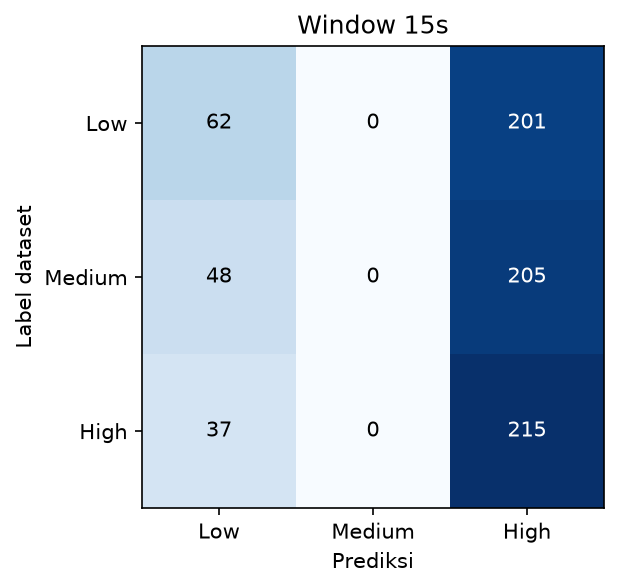

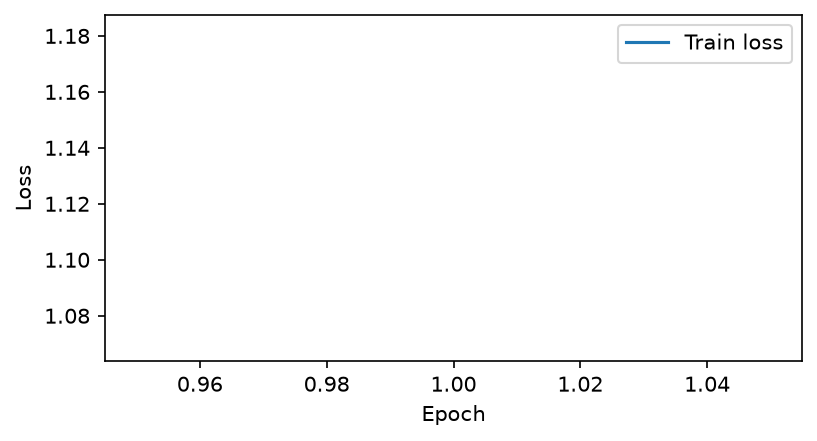


Test: selection_w15_dummy


,class,precision,recall,f1-score,support
0,Low,0.0000,0.0000,0.0000,263.0000
1,Medium,0.0000,0.0000,0.0000,253.0000
2,High,0.3281,1.0000,0.4941,252.0000
3,accuracy,0.3281,0.3281,0.3281,0.3281
4,macro avg,0.1094,0.3333,0.1647,768.0000
5,weighted avg,0.1077,0.3281,0.1621,768.0000


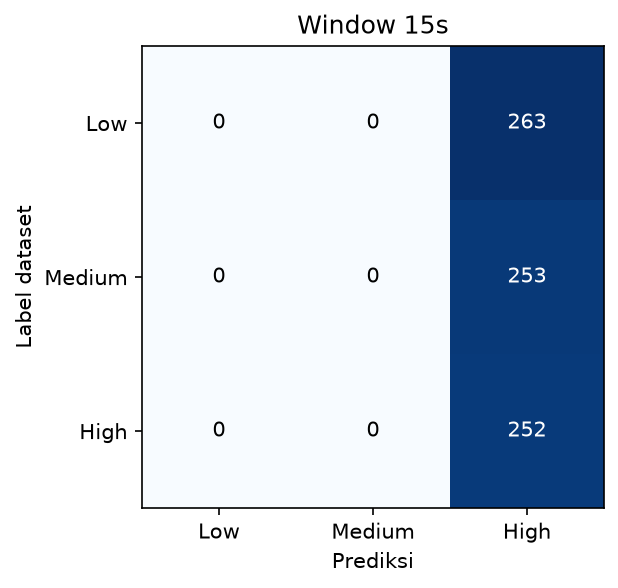


Test: selection_w25_6283118af04c3f0f_single


,class,precision,recall,f1-score,support
0,Low,0.4894,0.3866,0.4319,238.0000
1,Medium,0.2098,0.1422,0.1695,211.0000
2,High,0.2983,0.4487,0.3584,234.0000
3,accuracy,0.3324,0.3324,0.3324,0.3324
4,macro avg,0.3325,0.3258,0.3199,683.0000
5,weighted avg,0.3375,0.3324,0.3256,683.0000


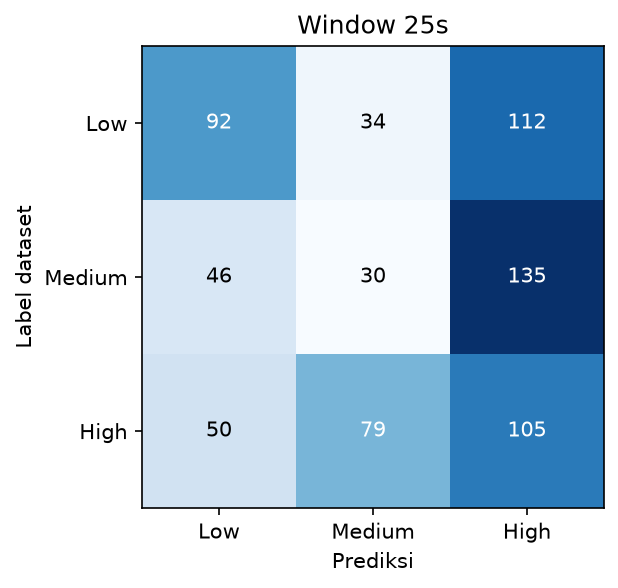

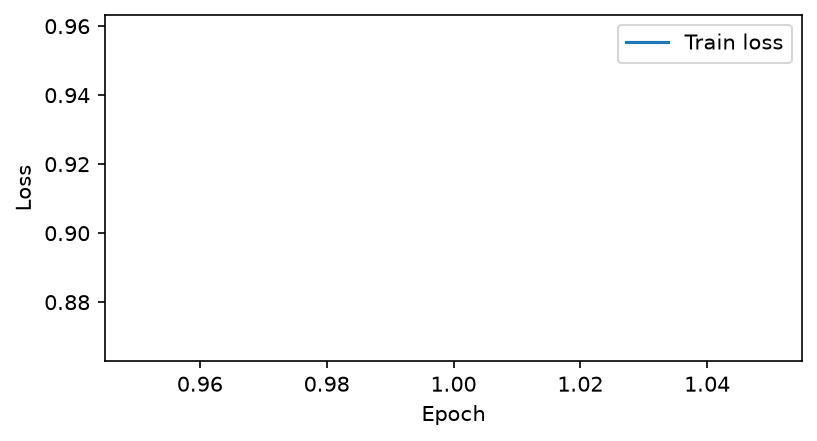


Test: selection_w25_dummy


,class,precision,recall,f1-score,support
0,Low,0.0000,0.0000,0.0000,238.0000
1,Medium,0.0000,0.0000,0.0000,211.0000
2,High,0.3426,1.0000,0.5104,234.0000
3,accuracy,0.3426,0.3426,0.3426,0.3426
4,macro avg,0.1142,0.3333,0.1701,683.0000
5,weighted avg,0.1174,0.3426,0.1749,683.0000


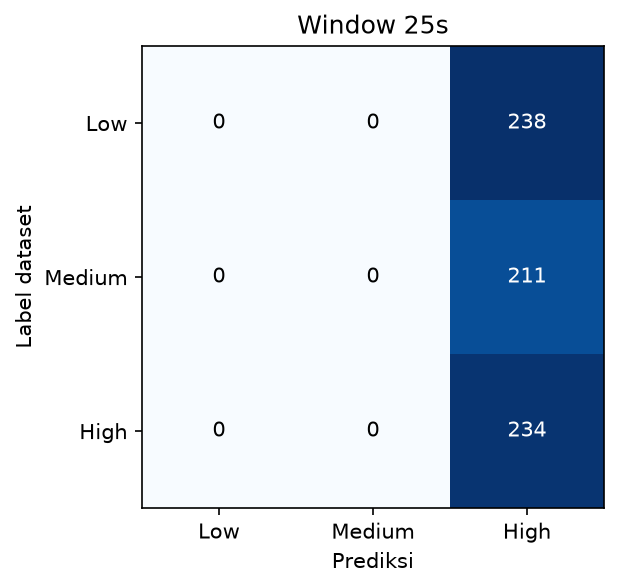


Test: selection_w45_447044003f18e07a_seeds


,class,precision,recall,f1-score,support
0,Low,0.6792,0.6698,0.6745,215.000
1,Medium,0.2313,0.2787,0.2528,122.000
2,High,0.3471,0.3073,0.3260,192.000
3,accuracy,0.4480,0.4480,0.4480,0.448
4,macro avg,0.4192,0.4186,0.4177,529.000
5,weighted avg,0.4554,0.4480,0.4507,529.000


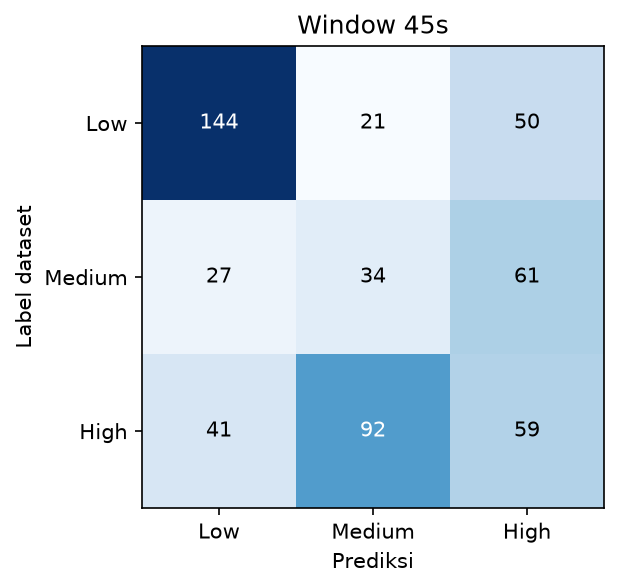

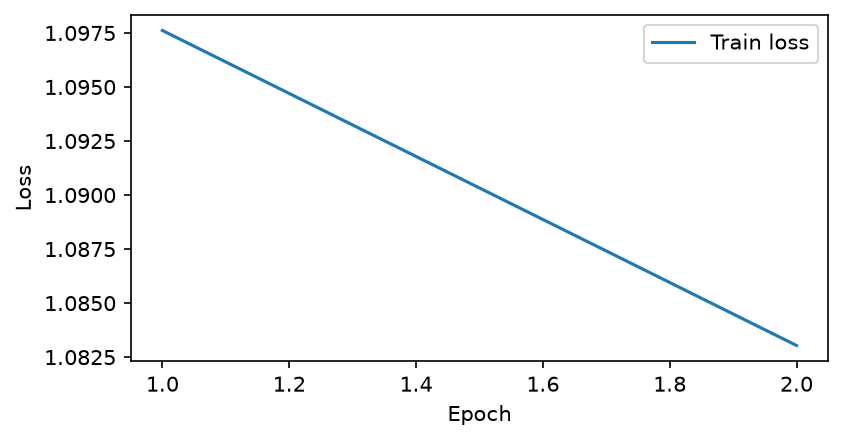


Test: selection_w45_dummy


,class,precision,recall,f1-score,support
0,Low,0.4064,1.0000,0.5780,215.0000
1,Medium,0.0000,0.0000,0.0000,122.0000
2,High,0.0000,0.0000,0.0000,192.0000
3,accuracy,0.4064,0.4064,0.4064,0.4064
4,macro avg,0.1355,0.3333,0.1927,529.0000
5,weighted avg,0.1652,0.4064,0.2349,529.0000


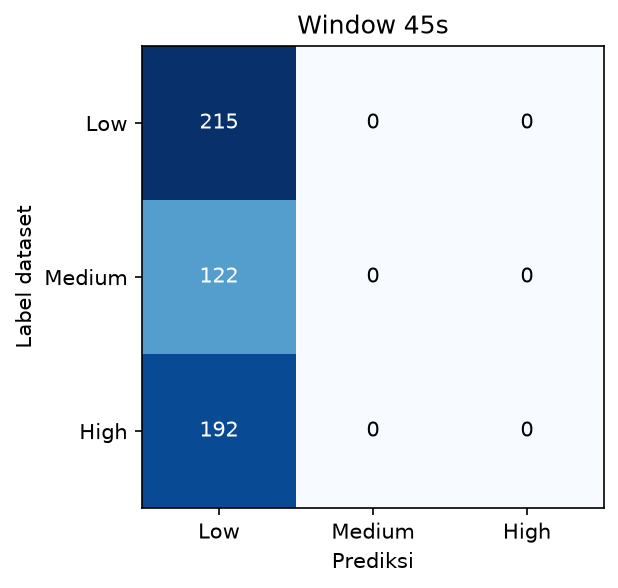

,id,window,test_rows,primary,window_winner,validation_accuracy,accuracy,macro_f1,balanced_accuracy,minimum_recall,model_sha256
0,selection_w15_4da0730795d65acb_single,15,768,False,True,0.4269,0.3607,0.2650,0.3630,0.0000,7490ddbd82c49f6c9d58a08a71ae534eacf58620a2566f...
1,selection_w15_dummy,15,768,False,False,0.3629,0.3281,0.1647,0.3333,0.0000,33b5da17de24c9e8ad3df67a303208f29dbb2f6859bc22...
2,selection_w25_6283118af04c3f0f_single,25,683,False,True,0.4067,0.3324,0.3199,0.3258,0.1422,99b51bcd485530c52417cb965cec38aea08b99711664bc...
3,selection_w25_dummy,25,683,False,False,0.3556,0.3426,0.1701,0.3333,0.0000,25c3796beda1d36248485d3adb09abbe3fcc5329fac7fd...
4,selection_w45_447044003f18e07a_seeds,45,529,True,True,0.4961,0.4480,0.4177,0.4186,0.2787,6a4c9c9fa0bbcde4df5151d06bcea1ac249dfc053bd67a...
5,selection_w45_dummy,45,529,False,False,0.3622,0.4064,0.1927,0.3333,0.0000,a74ab35073baa59d7870faed787adfba8b35e9f17e3401...


In [14]:
test_summary = evaluate_test(store, views, selection)

## Prediksi dengan Model Tersimpan

Muat bundle dengan definisi pipeline dan environment yang sama. Model riwayat memerlukan urutan sensor sebelumnya; model satu-window hanya memerlukan fitur saat ini. Gunakan hanya model terpercaya.

In [15]:
_chosen = selection['primary']
_record = store.read(_chosen)
_model = unpack_model(store.artifact(_chosen, 'model.pkl'))
_frame = views[_record['window']]
_ids = np.flatnonzero(_frame._split.eq('test'))[:3]
_output = predict_model(_model, _frame, _ids)
display(pd.DataFrame({'window_id': _frame.iloc[_ids].window_id.to_numpy(), 'prediction': np.asarray(LABELS)[_output['labels']]}))

,window_id,prediction
0,20261026_143707_P01_coding_task|2026-10-26T14:...,Medium
1,20261026_143707_P01_coding_task|2026-10-26T14:...,Medium
2,20261026_143707_P01_coding_task|2026-10-26T14:...,Medium
